<a href="https://colab.research.google.com/github/Vishali-Vivek006/Engineering-employability-prediction/blob/main/notebooks/employability_skill_gap_analysis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Employability Core — Colab notebook
Resume → validated model row → probability → SHAP, using your **existing** saved preprocessor + model (nothing is refit).

**Files you need to upload:**
1. `skills_registry.py`  ← imported by the code (`SKILLS`, `MODEL_TECH_SKILL_KEYS`, `MODEL_PROFILE_FIELDS`, `SOFT_SKILL_COLUMNS`, `display_name`)
2. your saved model `.joblib` and fitted preprocessor `.joblib` (from the **same** training run)
3. *(optional)* the training dataset CSV (SHAP background + validation)
4. *(optional)* a resume `.pdf` / `.docx`

The module in step 3 is your code, unchanged.

## 1. Install dependencies

In [1]:
!pip -q install shap pypdf python-docx joblib
# Use the same scikit-learn version that created your .joblib files, e.g.
# !pip -q install scikit-learn==<version>

## 2. Upload your files

In [2]:
from google.colab import files
uploaded = files.upload()   # skills_registry.py, model .joblib, preprocessor .joblib, dataset .csv, resume
print(list(uploaded))

[]


## 3. `employability_core.py` (unchanged)

In [3]:
%%writefile employability_core.py
"""
employability_core.py
=====================
Resume -> validated model row -> probability -> SHAP, reusing the EXISTING saved
preprocessor + model. Nothing here fits the preprocessor or retrains the model.

Pipeline assumed (verified at run time by audit_artifacts, not hard-coded):
    raw row (153 cols) --preprocessor--> 169 features --model Pipeline(scaler, LogisticRegression)
"""
import io
import os
import re
import base64
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from skills_registry import (SKILLS, MODEL_TECH_SKILL_KEYS, MODEL_PROFILE_FIELDS,
                             SOFT_SKILL_COLUMNS, display_name)

TARGET_COL = "Placement_Status"
LEAKAGE_COLS = {"Student_ID", "Data_Source", "Placement_Status"}
PLACED_CANDIDATES = (1, "1", "Placed", "placed", True)

# Fields without which no prediction is shown (never silently imputed).
CRITICAL_FIELDS = ["Education_Level", "UG_Degree", "Branch", "Year", "CGPA",
                   "Backlogs", "Internship", "Project_Count"]


class ArtifactError(RuntimeError):
    """Missing / incompatible model artifacts."""


class ResumeError(RuntimeError):
    """Unreadable or unsupported resume."""


class InputValidationError(ValueError):
    """The student row cannot safely be sent to the model."""


# =============================================================================
# 1. ARTIFACTS + AUDIT
# =============================================================================
def load_artifacts(model_path, preprocessor_path):
    for label, p in (("trained model", model_path), ("fitted preprocessor", preprocessor_path)):
        if not os.path.exists(p):
            raise ArtifactError(
                f"Missing {label}: {p}\nRecovery: re-export it from the training notebook with "
                f"joblib.dump(<object>, '{os.path.basename(p)}') and upload it to the same folder. "
                f"The model and preprocessor MUST come from the same training run.")
    try:
        return joblib.load(model_path), joblib.load(preprocessor_path)
    except Exception as e:  # version mismatch, corrupt file, ...
        raise ArtifactError(f"Could not unpickle artifacts ({type(e).__name__}: {e}). "
                            "Use the same scikit-learn version that created them.") from e


def final_estimator(model):
    return model.steps[-1][1] if hasattr(model, "steps") else model


def pre_model_steps(model):
    """Steps of the model Pipeline that run before the final estimator (e.g. the scaler)."""
    if hasattr(model, "steps") and len(model.steps) > 1:
        from sklearn.pipeline import Pipeline
        return Pipeline(model.steps[:-1])
    return None


def resolve_placed_index(model):
    """Index of the 'Placed' class in model.classes_ (never assume column order)."""
    classes = list(getattr(model, "classes_", []))
    for i, c in enumerate(classes):
        if isinstance(c, (bool, np.bool_, int, np.integer)) and int(c) == 1:
            return i
        if isinstance(c, str) and c.strip().lower() in ("1", "placed"):
            return i
    raise ArtifactError(f"Cannot identify the 'Placed' class in model.classes_={classes}. "
                        "Expected 1 or 'Placed'.")


def _find_in_transformer(obj, attr):
    """Find first sub-estimator (searching Pipeline steps) that has fitted attribute `attr`."""
    if hasattr(obj, attr):
        return obj
    for _, step in getattr(obj, "steps", []):
        r = _find_in_transformer(step, attr)
        if r is not None:
            return r
    return None


def categorical_info(preprocessor):
    """{raw categorical column: [valid categories]} + handle_unknown flag, from the FITTED encoder."""
    cats, handle = {}, {}
    for name, trans, cols in preprocessor.transformers_:
        if name == "remainder" or trans in ("drop", "passthrough"):
            continue
        enc = _find_in_transformer(trans, "categories_")
        if enc is not None:
            for c, cat in zip(cols, enc.categories_):
                cats[c] = [str(x) for x in cat]
                handle[c] = getattr(enc, "handle_unknown", "error")
    return cats, handle


def imputer_fill_values(preprocessor):
    """{raw column: value the fitted imputer will substitute if the field is missing}."""
    fills = {}
    for name, trans, cols in preprocessor.transformers_:
        if name == "remainder" or trans in ("drop", "passthrough"):
            continue
        imp = _find_in_transformer(trans, "statistics_")
        if imp is not None:
            for c, v in zip(cols, imp.statistics_):
                fills[c] = v
    return fills


def clean_feature_names(preprocessor):
    try:
        names = list(preprocessor.get_feature_names_out())
    except Exception as e:
        raise ArtifactError(f"preprocessor.get_feature_names_out() failed: {e}")
    return [re.sub(r"^(num|cat|remainder)__", "", n) for n in names]


def column_groups(raw_columns):
    """Classify raw model columns. Unknown columns are returned, never ignored."""
    cols = set(raw_columns)
    g = {"tech_skills": [c for c in MODEL_TECH_SKILL_KEYS if c in cols]}
    for k, v in MODEL_PROFILE_FIELDS.items():
        g[k] = [c for c in v if c in cols]
    known = {c for v in g.values() for c in v}
    g["unclassified"] = [c for c in raw_columns if c not in known]
    return g


def audit_artifacts(model, preprocessor, alt_model=None, df=None):
    """Return a dict describing what was found and every integration problem detected."""
    issues, notes = [], []
    raw = list(getattr(preprocessor, "feature_names_in_", []))
    if not raw:
        issues.append("Preprocessor has no feature_names_in_ (fit it on a DataFrame).")
    out_names = clean_feature_names(preprocessor)
    n_in = getattr(model, "n_features_in_", None)
    if n_in is not None and n_in != len(out_names):
        issues.append(f"Model expects {n_in} features but preprocessor emits {len(out_names)}: "
                      "wrong model/preprocessor pair.")
    est = final_estimator(model)
    info = dict(model_type=type(model).__name__, final_estimator=type(est).__name__,
                pipeline_steps=[n for n, _ in getattr(model, "steps", [])],
                classes=list(getattr(model, "classes_", [])), n_raw=len(raw),
                n_processed=len(out_names), n_model_features=n_in,
                supports_predict_proba=hasattr(model, "predict_proba"))
    if not info["supports_predict_proba"]:
        issues.append("Model lacks predict_proba(): decision scores are NOT calibrated probabilities.")
    try:
        info["placed_index"] = resolve_placed_index(model)
    except ArtifactError as e:
        issues.append(str(e))
    cats, handle = categorical_info(preprocessor)
    info["categorical_columns"] = cats
    info["handle_unknown"] = handle
    info["groups"] = column_groups(raw)
    if info["groups"]["unclassified"]:
        issues.append("Model columns not recognised by the registry (will be asked, never zero-filled): "
                      f"{info['groups']['unclassified']}")
    miss_skill_cols = [c for c in MODEL_TECH_SKILL_KEYS if c not in raw]
    if miss_skill_cols:
        notes.append(f"Registry skills absent from model schema (ignored for prediction): {miss_skill_cols}")
    bad_cat = [c for c in cats if c not in raw]
    if bad_cat:
        issues.append(f"Categorical columns not in raw schema: {bad_cat}")
    leak = [c for c in raw if c in LEAKAGE_COLS]
    if leak:
        issues.append(f"Leakage columns used as model inputs: {leak}")
    notes.append("Role-context inputs exist in the model ("
                 f"{info['groups']['role_context'] + ['Relevant_Project_Count', 'Relevant_Certification_Count']}): "
                 "the employability score therefore depends on how the student answers these 4 questions.")
    # Compare two candidate model files
    if alt_model is not None:
        same = (type(alt_model).__name__ == type(model).__name__
                and getattr(alt_model, "n_features_in_", None) == n_in
                and list(getattr(alt_model, "classes_", [])) == info["classes"])
        diff = None
        try:
            a, b = final_estimator(model).coef_, final_estimator(alt_model).coef_
            diff = float(np.max(np.abs(a - b))) if a.shape == b.shape else "shape differs"
        except Exception:
            pass
        info["alt_model_comparison"] = dict(compatible=same, max_abs_coef_difference=diff)
        notes.append("Two model files were supplied. "
                     + ("They are numerically identical." if diff == 0.0 else
                        "They differ: choose explicitly (see alt_model_comparison); do not mix them."))
    if df is not None:
        info["dataset"] = audit_dataset(df, raw, cats)
        issues += info["dataset"]["issues"]
    return dict(info=info, issues=issues, notes=notes)


def audit_dataset(df, raw_columns, cats):
    issues = []
    missing = [c for c in raw_columns if c not in df.columns]
    if missing:
        issues.append(f"Dataset lacks model input columns: {missing[:10]}")
    if TARGET_COL not in df.columns:
        issues.append(f"Target column '{TARGET_COL}' not found.")
    rep = dict(n_rows=len(df), n_duplicate_rows=int(df.duplicated().sum()),
               target_distribution=(df[TARGET_COL].value_counts(normalize=True).round(3).to_dict()
                                    if TARGET_COL in df.columns else None),
               leakage_columns_present=[c for c in df.columns if c in LEAKAGE_COLS],
               missing_cells_pct=round(float(df[[c for c in raw_columns if c in df.columns]].isna().mean().mean()) * 100, 2))
    if "Data_Source" in df.columns:
        rep["data_source_values"] = df["Data_Source"].value_counts().to_dict()
    for c, valid in cats.items():
        if c in df.columns:
            unseen = set(df[c].dropna().astype(str)) - set(valid)
            if unseen:
                issues.append(f"{c}: dataset contains categories unknown to the fitted encoder: {sorted(unseen)[:5]}")
    rep["issues"] = issues
    return rep


def profile_dataset(df, raw_columns):
    """Per-column kind/range, used to build the input form from real data (not assumptions)."""
    prof = {}
    for c in raw_columns:
        if c not in df.columns:
            continue
        s = df[c].dropna()
        if s.dtype == object or str(s.dtype).startswith(("string", "category")):
            prof[c] = dict(kind="categorical", values=sorted(map(str, s.unique()))[:50])
        else:
            u = set(np.unique(s.to_numpy()))
            kind = "binary" if u <= {0, 1, 0.0, 1.0} else "continuous"
            prof[c] = dict(kind=kind, min=float(s.min()), max=float(s.max()),
                           missing_pct=round(float(df[c].isna().mean()) * 100, 2))
    return prof


# =============================================================================
# 2. RESUME TEXT + FIELD EXTRACTION
# =============================================================================
def _normalise_bullets(text):
    """PDF/Word bullets come out as \\x7f, private-use glyphs, etc. Map them all to '•'."""
    return re.sub(rf"[{_BULLET_GLYPHS}]", "•", text)


def extract_text(path):
    path = str(path)
    if not os.path.exists(path):
        raise ResumeError(f"File not found: {path}")
    ext = Path(path).suffix.lower()
    if ext == ".pdf":
        try:
            from pypdf import PdfReader
            reader = PdfReader(path)
            if reader.is_encrypted and not reader.decrypt(""):
                raise ResumeError("PDF is password-protected.")
            text = "\n".join((p.extract_text() or "") for p in reader.pages)
        except ResumeError:
            raise
        except Exception as e:
            raise ResumeError(f"Could not read PDF ({type(e).__name__}: {e}).") from e
        if len(text.strip()) < 30:
            raise ResumeError("No extractable text (likely a scanned/image PDF). OCR is required; "
                              "or paste the text / upload a DOCX instead.")
        return _normalise_bullets(text)
    if ext == ".docx":
        try:
            import docx
            d = docx.Document(path)
            parts = [p.text for p in d.paragraphs]
            for t in d.tables:
                for row in t.rows:
                    parts.append(" | ".join(c.text.strip() for c in row.cells))
            text = "\n".join(parts)
        except Exception as e:
            raise ResumeError(f"Could not read DOCX ({type(e).__name__}: {e}).") from e
        if len(text.strip()) < 30:
            raise ResumeError("DOCX contains no readable text.")
        return _normalise_bullets(text)
    raise ResumeError(f"Unsupported file type '{ext}'. Upload a .pdf or .docx resume.")


_HEADINGS = {
    "education": r"education(?:al)?(?: qualifications?| background)?|academic (?:background|qualifications?)",
    "skills": r"(?:technical |key )?skills(?: summary)?|technical proficienc(?:y|ies)|core competenc(?:y|ies)|tools(?: and technologies)?",
    "projects": r"(?:academic |personal |key )?projects?",
    "internships": r"internships?|work experience|professional experience|experience|training",
    "certifications": r"certifications?|certificates?|licen[cs]es?(?: and certifications?)?|courses",
    "achievements": r"achievements?|awards?|honou?rs|extra[- ]?curricular(?: activities)?|activities|positions? of responsibility|hackathons?",
    "other": r"summary|objective|profile|declaration|references|languages|interests|personal details",
}
_HEAD_RE = {k: re.compile(rf"^\W*(?:{v})\W*$", re.I) for k, v in _HEADINGS.items()}


def heading_of(line):
    s = line.strip()
    if 2 < len(s) <= 45:
        for k, rx in _HEAD_RE.items():
            if rx.match(s):
                return k
    return None


def segment_sections(text):
    sections, cur = {"header": []}, "header"
    for line in text.splitlines():
        h = heading_of(line)
        if h:
            cur = h
            sections.setdefault(cur, [])
        else:
            sections.setdefault(cur, []).append(line)
    return {k: "\n".join(v).strip() for k, v in sections.items()}


# ---- skill detection --------------------------------------------------------
def _alias_regex(alias, ambiguous):
    toks = [re.escape(t) for t in alias.split()]
    body = r"[\s\-]+".join(toks)
    return re.compile(rf"(?<![A-Za-z0-9+#]){body}(?![A-Za-z0-9+#])", 0 if ambiguous else re.I)


_PATTERNS = [(key, alias, _alias_regex(alias, s["ambiguous"]), s["ambiguous"])
             for key, s in SKILLS.items() for alias in s["aliases"]]


def detect_skills(text):
    """{skill_key: {'confidence': 'high'|'low', 'evidence': [matched strings]}}"""
    found = {}
    for key, alias, rx, amb in _PATTERNS:
        for m in rx.finditer(text):
            d = found.setdefault(key, dict(confidence="low" if amb else "high", evidence=[]))
            if not amb:
                d["confidence"] = "high"
            if m.group(0) not in d["evidence"] and len(d["evidence"]) < 3:
                d["evidence"].append(m.group(0))
    return found


# exact-alias mapping for the EXISTING extractor's technical_skills list
# (fixes the legacy bug where normalising "C++" -> "c" collided with "C")
_EXACT = {}
for _k, _s in SKILLS.items():
    for _a in [_s["display"]] + _s["aliases"] + [_k]:
        _EXACT.setdefault(_a.strip().lower(), _k)
_EXACT["c"] = "C"        # case handled by exact lowercase lookup, never by stripping punctuation
_EXACT["c++"] = "Cpp"


def map_skill_names(names):
    mapped, unmapped = {}, []
    for n in names:
        k = _EXACT.get(str(n).strip().lower())
        if k:
            mapped[k] = dict(confidence="high", evidence=[str(n)])
        else:
            unmapped.append(str(n))
    return mapped, unmapped


# ---- education / CGPA / counts ---------------------------------------------
_BRANCH_PATTERNS = [("CSE", r"(?i:computer science|computer engineering)|\bC\.?S\.?E\b"),
                    ("IT", r"(?i:information technology)|\bI\.?T\b"),
                    ("ECE", r"(?i:electronics (?:and|&) communication)|\bECE\b"),
                    ("EEE", r"(?i:electrical (?:and|&) electronics|electrical engineering)|\bEEE\b"),
                    ("Mechanical", r"(?i:mechanical)"), ("Civil", r"(?i:\bcivil\b)"),
                    ("Aerospace", r"(?i:aerospace|aeronautical)")]


def parse_education(text, education_mentions=()):
    blob = text + "\n" + " ".join(map(str, education_mentions))
    ug = re.search(r"\bB\.?\s?Tech\b|\bB\.\s?E\b\.?|\bBE\b|bachelor", blob, re.I)
    pg = re.search(r"\bM\.?\s?Tech\b|\bM\.\s?E\b|\bMCA\b|\bMBA\b|\bmaster", blob, re.I)
    level = None
    notes = []
    if ug and pg:
        notes.append("Both UG and PG degrees are mentioned: confirm the CURRENT level.")
    elif ug:
        level = "UG"
    elif pg:
        level = "PG"
    branches = [b for b, rx in _BRANCH_PATTERNS if re.search(rx, blob)]
    if len(branches) > 1:
        notes.append(f"Several branch keywords found {branches}: confirm your branch.")
    return dict(level_guess=level, branch_candidates=branches, notes=notes,
                degree_text=(ug or pg).group(0) if (ug or pg) else None)


def parse_cgpa(text, cgpa_mentions=()):
    blob = text + "\n" + "\n".join(map(str, cgpa_mentions))
    cands = []
    for m in re.finditer(r"(?:C\.?G\.?P\.?A|GPA)\s*[:\-–]?\s*(\d{1,2}(?:\.\d{1,3})?)(?:\s*/\s*(\d{1,2}(?:\.\d+)?))?", blob, re.I):
        cands.append((float(m.group(1)), float(m.group(2)) if m.group(2) else None))
    for m in re.finditer(r"(\d{1,2}(?:\.\d{1,3})?)\s*/\s*(10|4)\s*(?:C\.?G\.?P\.?A)?", blob, re.I):
        cands.append((float(m.group(1)), float(m.group(2))))
    uniq = []
    for c in cands:
        if c not in uniq:
            uniq.append(c)
    valid = [v for v, sc in uniq if (sc in (None, 10.0)) and 0 < v <= 10]
    other_scale = [(v, sc) for v, sc in uniq if sc not in (None, 10.0) or v > 10]
    return dict(candidates=uniq, best=valid[0] if len(set(valid)) == 1 else None,
                ambiguous=len(set(valid)) > 1,
                non_10_scale=other_scale)


_BULLET_GLYPHS = "\x7f\x95\uf000-\uf8ff●○■□➢➤❖▪◦·"
_BULLET = re.compile(rf"^\s*(?:[•\-\*–—{_BULLET_GLYPHS}])\s*")


def _is_bullet(line):
    return bool(_BULLET.match(line))


def _cut_at_other_heading(section_text, own):
    out = []
    for line in section_text.splitlines():
        h = heading_of(line)
        if h and h != own:
            break
        out.append(line)
    return "\n".join(out)


def estimate_project_count(section_text):
    """Title-line heuristic (a title: non-bullet, starts a block, followed by a bullet). Estimate only."""
    section = _cut_at_other_heading(section_text or "", "projects")
    lines = [l.strip() for l in section.splitlines() if l.strip()]
    n = 0
    for i, l in enumerate(lines):
        if _is_bullet(l) or len(l) > 110 or re.match(r"(?i)(technolog|tech stack|tools)", l):
            continue
        prev_ok = (i == 0) or lines[i - 1].rstrip().endswith((".", "!"))
        nxt_b = i + 1 < len(lines) and _is_bullet(lines[i + 1])
        if prev_ok and nxt_b and not l.endswith("."):
            n += 1
    return n


def estimate_certification_count(section_text):
    lines = [l for l in (section_text or "").splitlines() if l.strip()]
    bullets = [l for l in lines if _is_bullet(l)]
    return len(bullets) if bullets else len(lines)


def internship_signals(section_text):
    t = section_text or ""
    has_kw = bool(re.search(r"\bintern(?:ship)?\b|\btrainee\b", t, re.I))
    dur = re.search(r"(\d+(?:\.\d+)?)\s*(months?|weeks?)", t, re.I)
    months = None
    if dur:
        v = float(dur.group(1))
        months = round(v / 4.345, 1) if dur.group(2).lower().startswith("week") else v
    return dict(section_present=bool(t.strip()), internship_keyword=has_kw,
                duration_months_candidate=months,
                note=(None if has_kw or not t.strip() else
                      "The section labelled experience/internship contains NO 'intern' keyword and looks "
                      "like project work: not treated as an internship."))


def extract_resume(path=None, existing_json=None, text=None, filename=None):
    """
    Produce the extraction dict (same keys as the existing resume_extraction_output.json
    + extra evidence fields). Pass `existing_json` to reuse output from the project's own
    extractor; pass `path` (PDF/DOCX) to run the built-in fallback extractor.
    """
    notes = []
    if existing_json is not None:
        ex = dict(existing_json)
        text = text or "\n".join(str(ex.get(k, "")) for k in
                                 ("project_section", "internship_section", "certification_section"))
        mapped, unmapped = map_skill_names(ex.get("technical_skills", []))
        detections = mapped
        if unmapped:
            notes.append(f"Extractor skills outside the registry (kept, not scored): {unmapped}")
        sections = {"projects": ex.get("project_section", ""), "internships": ex.get("internship_section", ""),
                    "certifications": ex.get("certification_section", "")}
        fname = ex.get("resume_filename", filename or "existing_json")
        edu_m, cg_m = ex.get("education_mentions", []), ex.get("cgpa_mentions", [])
        notes.append("Skills come from your existing extraction JSON; no re-parsing of the PDF was done.")
    else:
        if text is None:
            text = extract_text(path)
        fname = filename or (os.path.basename(str(path)) if path else "pasted_text")
        sections = segment_sections(text)
        detections = detect_skills(text)
        edu_m, cg_m = [], []
        if not sections.get("projects"):
            notes.append("No 'Projects' heading found: project count must be entered manually.")
    full = text or ""
    edu = parse_education(full, edu_m)
    cgpa = parse_cgpa(full, cg_m)
    internship = internship_signals(sections.get("internships", ""))
    if internship["note"]:
        notes.append(internship["note"])
    if cgpa["non_10_scale"]:
        notes.append(f"CGPA found on a non-10 scale / >10: {cgpa['non_10_scale']} – not auto-converted.")
    by_cat = {}
    for k in detections:
        by_cat.setdefault(SKILLS[k]["domain"], []).append(display_name(k))
    return dict(
        resume_filename=fname,
        education_mentions=edu_m or ([edu["degree_text"]] if edu["degree_text"] else []),
        cgpa_mentions=cg_m or [f"CGPA {c[0]}" for c in cgpa["candidates"]],
        technical_skills=sorted(display_name(k) for k in detections),
        skills_by_category=by_cat,
        project_section=sections.get("projects", ""),
        internship_section=sections.get("internships", ""),
        certification_section=sections.get("certifications", ""),
        # --- extras produced by this module ---
        skill_detections=detections,
        education=edu, cgpa=cgpa, internship=internship,
        project_count_estimate=estimate_project_count(sections.get("projects", "")),
        certification_count_estimate=estimate_certification_count(sections.get("certifications", "")),
        hackathon_mention=bool(re.search(r"hackathon", full, re.I)),
        open_source_mention=bool(re.search(r"open[- ]source", full, re.I)),
        text_chars=len(full), parsing_notes=notes,
    )


# =============================================================================
# 3. PROFILE -> EXACT MODEL ROW
# =============================================================================
class StudentProfile:
    """
    Holds confirmed answers. Each field has a status:
      provided | confirmed_absent | not_applicable | unknown
    Each skill has a state: present | absent (confirmed) | unknown (not found / not confirmed).
    """

    def __init__(self):
        self.fields = {}        # col -> dict(value, status, source)
        self.skill_state = {}   # canonical key -> present|absent|unknown
        self.extra_present = set()

    def set(self, col, value, status="provided", source="user"):
        self.fields[col] = dict(value=value, status=status, source=source)

    def set_unknown(self, col):
        self.fields[col] = dict(value=None, status="unknown", source="not provided")

    def value(self, col):
        f = self.fields.get(col)
        return None if f is None or f["status"] == "unknown" else f["value"]

    def present_skills(self):
        return {k for k, v in self.skill_state.items() if v == "present"}


def apply_skill_review(profile, detections, confirmed_present, confirmed_absent=(), absent_domains=(), all_keys=None):
    """
    confirmed_present: keys the student ticked (parser-detected AND user-added).
    confirmed_absent : keys the student explicitly says they lack.
    absent_domains   : domains where the student confirms 'anything I did not tick, I do not have'.
    Everything else stays 'unknown' (NOT zero).
    """
    keys = all_keys or list(SKILLS)
    for k in keys:
        if k in confirmed_present:
            profile.skill_state[k] = "present"
        elif k in confirmed_absent or SKILLS[k]["domain"] in absent_domains:
            profile.skill_state[k] = "absent"
        else:
            profile.skill_state[k] = "unknown"
    return profile


def build_raw_row(profile, raw_columns, cat_info, handle_unknown):
    """
    Returns (DataFrame with EXACTLY raw_columns in order, report dict).
    - skills: present->1, absent->0, unknown->NaN (preprocessor imputer decides; flagged)
    - categorical: must map to a fitted category (case-insensitive) or error
    """
    row, errors, warnings_ = {}, [], []
    for c in raw_columns:
        if c in cat_info:
            v = profile.value(c)
            if v is None:
                row[c] = np.nan
                continue
            m = {x.lower().strip(): x for x in cat_info[c]}
            hit = m.get(str(v).lower().strip())
            if hit is None:
                msg = f"{c}='{v}' is not a category seen in training {cat_info[c]}."
                (warnings_ if handle_unknown.get(c) == "ignore" else errors).append(msg)
                row[c] = str(v)
            else:
                row[c] = hit
        elif c in SKILLS and c in MODEL_TECH_SKILL_KEYS:
            st = profile.skill_state.get(c, "unknown")
            row[c] = 1.0 if st == "present" else 0.0 if st == "absent" else np.nan
        else:
            v = profile.value(c)
            if v is None:
                row[c] = np.nan
            else:
                try:
                    row[c] = float(v)
                except (TypeError, ValueError):
                    errors.append(f"{c}='{v}' is not numeric.")
                    row[c] = np.nan
    df = pd.DataFrame([row], columns=list(raw_columns))
    missing_crit = [c for c in CRITICAL_FIELDS if c in raw_columns and pd.isna(df.iloc[0][c])]
    if df.iloc[0].get("Internship") == 1 and "Internship_Duration_Months" in raw_columns \
            and pd.isna(df.iloc[0]["Internship_Duration_Months"]):
        missing_crit.append("Internship_Duration_Months")
    errors += [f"Required field not provided: {c}" for c in missing_crit]
    # logical consistency
    g = lambda c: df.iloc[0][c] if c in df.columns else np.nan
    for rel, tot in (("Relevant_Project_Count", "Project_Count"),
                     ("Relevant_Certification_Count", "Certification_Count")):
        if pd.notna(g(rel)) and pd.notna(g(tot)) and g(rel) > g(tot):
            errors.append(f"{rel} ({g(rel)}) cannot exceed {tot} ({g(tot)}).")
    if pd.notna(g("CGPA")) and not 0 <= g("CGPA") <= 10:
        errors.append("CGPA must be on the 0-10 scale used by the model.")
    if pd.notna(g("Internship")) and g("Internship") == 0 and pd.notna(g("Internship_Duration_Months")) \
            and g("Internship_Duration_Months") > 0:
        errors.append("Internship=0 but duration>0.")
    return df, dict(errors=errors, warnings=warnings_)


def imputation_report(X_raw, preprocessor):
    """Fields the model will fill with training statistics (NOT student-provided)."""
    fills = imputer_fill_values(preprocessor)
    rows = []
    for c in X_raw.columns:
        if pd.isna(X_raw.iloc[0][c]):
            fv = fills.get(c, "n/a")
            rows.append(dict(field=c, imputed_with=fv,
                             kind=("skill" if c in MODEL_TECH_SKILL_KEYS else
                                   "soft skill" if c in SOFT_SKILL_COLUMNS else "profile")))
    return pd.DataFrame(rows, columns=["field", "imputed_with", "kind"])


# =============================================================================
# 4. PREDICTION
# =============================================================================
def transform_dense(preprocessor, X_raw):
    Xp = preprocessor.transform(X_raw)
    if hasattr(Xp, "toarray"):
        Xp = Xp.toarray()
    return np.asarray(Xp, dtype=float)


def predict_employability(model, preprocessor, X_raw):
    expected = list(preprocessor.feature_names_in_)
    if list(X_raw.columns) != expected:
        raise InputValidationError("Input columns differ from the fitted preprocessor "
                                   f"(missing={sorted(set(expected) - set(X_raw.columns))[:5]}, "
                                   f"extra={sorted(set(X_raw.columns) - set(expected))[:5]}).")
    Xp = transform_dense(preprocessor, X_raw)
    n_in = getattr(model, "n_features_in_", Xp.shape[1])
    if Xp.shape[1] != n_in:
        raise InputValidationError(f"Preprocessor produced {Xp.shape[1]} features; model expects {n_in}.")
    if not np.isfinite(Xp).all():
        raise InputValidationError("Non-finite values after preprocessing.")
    if not hasattr(model, "predict_proba"):
        raise ArtifactError("Model has no predict_proba(); refusing to present scores as probabilities.")
    proba = np.asarray(model.predict_proba(Xp))[0]
    classes = list(model.classes_)
    pi = resolve_placed_index(model)
    ni = [i for i in range(len(classes)) if i != pi]
    if len(classes) != 2:
        raise ArtifactError("This module handles binary Placed / Not Placed models only.")
    if not (np.isfinite(proba).all() and (proba >= 0).all() and (proba <= 1).all()
            and abs(proba.sum() - 1) < 1e-6):
        raise InputValidationError(f"Invalid probability vector {proba}.")
    pred = model.predict(Xp)[0]
    pred_by_argmax = classes[int(np.argmax(proba))]
    p_placed, p_not = float(proba[pi]), float(proba[ni[0]])
    return dict(
        predicted_label=pred, predicted_class="Placed" if pred == classes[pi] else "Not Placed",
        p_placed=p_placed, p_not_placed=p_not, classes=classes, placed_index=pi,
        decision_rule_consistent=bool(pred == pred_by_argmax),
        decision_rule="model.predict(); for binary Logistic Regression this equals P(Placed) >= 0.5",
        processed_shape=Xp.shape,
        interpretation=(f"The model assigns an estimated {p_placed:.1%} probability to the Placed class and "
                        f"{p_not:.1%} to Not Placed, so its predicted class is "
                        f"{'Placed' if pred == classes[pi] else 'Not Placed'}. This is a score learned from "
                        "SYNTHETIC training data; it is not a validated real-world placement probability "
                        "and not a guarantee of any outcome."))


# =============================================================================
# 5. SHAP
# =============================================================================
def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def _background_matrix(model, preprocessor, background_df, n_background, seed=0):
    pre = pre_model_steps(model)
    if background_df is not None:
        raw = list(preprocessor.feature_names_in_)
        bg = background_df[raw]
        if len(bg) > n_background:
            bg = bg.sample(n_background, random_state=seed)
        Xp = transform_dense(preprocessor, bg)
        return pre.transform(Xp) if pre is not None else Xp, "dataset sample"
    from sklearn.preprocessing import StandardScaler
    scaler = pre.steps[-1][1] if pre is not None and len(pre.steps) == 1 else None
    if isinstance(scaler, StandardScaler) and scaler.with_mean:
        return np.zeros((2, len(scaler.mean_))), "training mean stored in the model's StandardScaler"
    return None, None


def explain_prediction(model, preprocessor, X_raw, background_df=None, n_background=300, top_n=8):
    import shap
    expected = list(preprocessor.feature_names_in_)
    if list(X_raw.columns) != expected:
        raise InputValidationError("Explaining a row whose columns differ from the prediction row.")
    names = clean_feature_names(preprocessor)
    Xp = transform_dense(preprocessor, X_raw)
    pre, est = pre_model_steps(model), final_estimator(model)
    Xm = pre.transform(Xp) if pre is not None else Xp
    pi = resolve_placed_index(model)
    bg, bg_desc = _background_matrix(model, preprocessor, background_df, n_background)
    kind = type(est).__name__

    if hasattr(est, "coef_") and kind in ("LogisticRegression", "SGDClassifier", "RidgeClassifier",
                                           "LinearSVC", "LogisticRegressionCV"):
        if bg is None:
            raise ArtifactError("Need background data (pass the dataset) to explain this linear model.")
        explainer = shap.LinearExplainer(est, shap.maskers.Independent(bg, max_samples=len(bg)))
        scale, explainer_name = "log-odds", "LinearExplainer (exact for linear models)"
        raw_vals = explainer.shap_values(Xm)
        raw_base = explainer.expected_value
        reference = est.decision_function(Xm)[0]
    elif kind in ("RandomForestClassifier", "ExtraTreesClassifier", "GradientBoostingClassifier",
                  "DecisionTreeClassifier", "XGBClassifier", "LGBMClassifier"):
        if bg is None:
            raise ArtifactError("Tree explanations need background data (pass the dataset).")
        explainer = shap.TreeExplainer(est, data=bg, feature_perturbation="interventional",
                                       model_output="probability")
        scale, explainer_name = "probability", "TreeExplainer (interventional, probability output)"
        raw_vals = explainer.shap_values(Xm, check_additivity=False)
        raw_base = explainer.expected_value
        reference = est.predict_proba(Xm)[0, pi]
    else:
        if bg is None:
            raise ArtifactError("Need background data (pass the dataset) for KernelExplainer.")
        f = lambda a: est.predict_proba(a)[:, pi]
        explainer = shap.KernelExplainer(f, shap.sample(bg, min(50, len(bg))))
        scale, explainer_name = "probability", "KernelExplainer (model-agnostic, approximate)"
        raw_vals = explainer.shap_values(Xm, nsamples=300)
        raw_base = explainer.expected_value
        reference = f(Xm)[0]

    # ---- normalise SHAP output formats to (n_features,) for the PLACED class -------
    if isinstance(raw_vals, list):                      # old API: list per class
        vals, base = np.asarray(raw_vals[pi])[0], np.atleast_1d(raw_base)[pi]
    else:
        arr = np.asarray(raw_vals)
        if arr.ndim == 3:                               # (n, features, classes)
            vals, base = arr[0, :, pi], np.atleast_1d(raw_base)[pi]
        else:                                           # (n, features) -> positive class = classes_[1]
            vals, base = arr[0], float(np.atleast_1d(raw_base)[0])
            if kind in ("LogisticRegression", "SGDClassifier", "RidgeClassifier", "LinearSVC",
                        "LogisticRegressionCV") and pi == 0:
                vals, base, reference = -vals, -base, -reference
    base = float(base)
    additivity_error = float(abs(base + vals.sum() - reference))
    tol = 1e-6 if scale == "log-odds" else 1e-2
    result = dict(
        explainer=explainer_name, background=bg_desc, scale=scale, base_value=base,
        output_value=base + float(vals.sum()), reference_output=float(reference),
        additivity_error=additivity_error, additivity_ok=bool(additivity_error <= tol),
        explained_class="Placed", feature_names=names, values=vals,
        base_probability=float(_sigmoid(base)) if scale == "log-odds" else base,
    )
    result["raw_table"] = aggregate_to_raw(vals, names, X_raw, preprocessor, imputation_report(X_raw, preprocessor))
    t = result["raw_table"]
    result["top_positive"] = t[t["shap"] > 0].head(top_n)
    result["top_negative"] = t[t["shap"] < 0].sort_values("shap").head(top_n)
    return result


def aggregate_to_raw(vals, processed_names, X_raw, preprocessor, imputed_df):
    """Sum one-hot columns back to their raw field so names/values are meaningful to a person."""
    cats, _ = categorical_info(preprocessor)
    raw_cols = list(X_raw.columns)
    imputed = set(imputed_df["field"]) if len(imputed_df) else set()
    owner = {}
    for n in processed_names:
        if n in raw_cols:
            owner[n] = n
        else:
            hit = [c for c in cats if n.startswith(c + "_")]
            owner[n] = max(hit, key=len) if hit else n
    agg = {}
    for n, v in zip(processed_names, vals):
        agg[owner[n]] = agg.get(owner[n], 0.0) + float(v)
    fills = imputer_fill_values(preprocessor)
    rows = []
    for c, v in agg.items():
        sv = X_raw.iloc[0][c] if c in X_raw.columns else np.nan
        was_imp = c in imputed
        shown = fills.get(c) if was_imp and pd.isna(sv) else sv
        rows.append(dict(feature=c, student_value=shown, shap=v, imputed=was_imp,
                         direction="toward Placed" if v > 0 else "away from Placed" if v < 0 else "neutral"))
    out = pd.DataFrame(rows)
    return out.reindex(out["shap"].abs().sort_values(ascending=False).index).reset_index(drop=True)


def _fmt(v):
    if isinstance(v, (float, np.floating)):
        return f"{v:g}" if not np.isnan(v) else "n/a"
    return str(v)


def explanation_text(pred, ex, top_n=5):
    unit = ("log-odds units (NOT percentage points)" if ex["scale"] == "log-odds"
            else "probability units")
    lines = [f"Model baseline (average training-like student): {ex['base_probability']:.1%} Placed. "
             f"This student's estimate is {pred['p_placed']:.1%}.",
             f"Contributions below are in {unit}; positive values push the model output toward Placed, "
             "negative values push it away. They describe the MODEL's behaviour, not causes of real placement."]

    def block(title, df):
        lines.append(title)
        if df.empty:
            lines.append("  (none)")
        for _, r in df.head(top_n).iterrows():
            tag = " [value NOT provided: model used typical training value]" if r["imputed"] else ""
            lines.append(f"  - {r['feature']} = {_fmt(r['student_value'])}: {r['shap']:+.3f}{tag}")
    block("Strongest factors pushing toward Placed:", ex["top_positive"])
    block("Strongest factors pushing away from Placed:", ex["top_negative"])
    n_imp = int(ex["raw_table"]["imputed"].sum())
    if n_imp:
        lines.append(f"Note: {n_imp} features were imputed rather than provided; treat their contributions as unverified.")
    return "\n".join(lines)


def _fig_to_b64(fig):
    import matplotlib.pyplot as plt
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=130, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()


def plot_shap_bar(ex, top_n=12):
    import matplotlib.pyplot as plt
    t = ex["raw_table"].head(top_n).iloc[::-1]
    colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in t["shap"]]
    labels = [f"{r.feature} = {_fmt(r.student_value)}" + ("*" if r.imputed else "") for r in t.itertuples()]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.3))
    ax.barh(labels, t["shap"], color=colors)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(f"SHAP value for class 'Placed' ({ex['scale']})")
    ax.set_title("Top feature contributions for this student (* = imputed, not provided)")
    return fig


def plot_shap_waterfall(ex, X_raw, max_display=12):
    """shap's own waterfall on the raw-feature level; falls back to cumulative bars."""
    import matplotlib.pyplot as plt
    import shap
    t = ex["raw_table"]
    try:
        exp = shap.Explanation(values=t["shap"].to_numpy(), base_values=ex["base_value"],
                               data=np.array([_fmt(v) for v in t["student_value"]], dtype=object),
                               feature_names=list(t["feature"]))
        shap.plots.waterfall(exp, max_display=max_display, show=False)
        fig = plt.gcf()
        fig.set_size_inches(8.5, 0.45 * max_display + 1.5)
        return fig
    except Exception:
        plt.close("all")
        top = t.head(max_display)
        fig, ax = plt.subplots(figsize=(8, 4))
        cum = ex["base_value"]
        for i, r in enumerate(top.itertuples()):
            ax.barh(i, r.shap, left=cum, color="#2a9d8f" if r.shap > 0 else "#e76f51")
            cum += r.shap
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(list(top["feature"]))
        ax.invert_yaxis()
        ax.axvline(ex["base_value"], ls="--", color="gray")
        ax.set_xlabel(f"cumulative output ({ex['scale']}) from baseline")
        return fig


# =============================================================================
# 6. VALIDATION OF THE MODEL ITSELF (discrimination + calibration)
# =============================================================================
def _metrics(y, p):
    from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score, accuracy_score,
                                 confusion_matrix, brier_score_loss, log_loss)
    pred = (p >= 0.5).astype(int)
    bins = np.linspace(0, 1, 11)
    idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
    ece = sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(10) if (idx == b).any())
    return dict(roc_auc=roc_auc_score(y, p), accuracy=accuracy_score(y, pred),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), brier=brier_score_loss(y, p),
                log_loss=log_loss(y, np.clip(p, 1e-12, 1 - 1e-12)), ece_10bin=float(ece),
                confusion_matrix=confusion_matrix(y, pred).tolist())


def evaluate_model(df, model, preprocessor, n_splits=5, seed=42):
    """
    (a) 'resubstitution': saved model on the full dataset - includes its own training rows, OPTIMISTIC.
        Its main use is catching a wrong model/preprocessor pair (AUC near 0.5).
    (b) 'cross_validated': CLONES of preprocessor+model scored out-of-fold (no leakage). The saved
        artifacts are untouched and nothing here calibrates or fits anything for a single student.
    """
    from sklearn.base import clone
    from sklearn.pipeline import Pipeline
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    from sklearn.calibration import calibration_curve
    import matplotlib.pyplot as plt
    raw = list(preprocessor.feature_names_in_)
    placed = model.classes_[resolve_placed_index(model)]
    X, y = df[raw], (df[TARGET_COL] == placed).astype(int).to_numpy()
    p_saved = model.predict_proba(transform_dense(preprocessor, X))[:, resolve_placed_index(model)]
    pipe = Pipeline([("pre", clone(preprocessor)), ("model", clone(model))])
    oof = cross_val_predict(pipe, X, y, cv=StratifiedKFold(n_splits, shuffle=True, random_state=seed),
                            method="predict_proba")[:, 1]
    res = dict(resubstitution=_metrics(y, p_saved), cross_validated=_metrics(y, oof), n=len(y),
               positive_rate=float(y.mean()))
    res["pair_check"] = ("OK" if res["resubstitution"]["roc_auc"] > 0.6 else
                         "SUSPICIOUS: saved model/preprocessor barely separate classes on this dataset - "
                         "likely a mismatched pair or target encoding.")
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for pp, lab, col in ((oof, "cross-validated (clones)", "C0"), (p_saved, "saved model, full data (optimistic)", "C1")):
        fr, mp = calibration_curve(y, pp, n_bins=10, strategy="quantile")
        ax[0].plot(mp, fr, "o-", label=lab, color=col)
    ax[0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax[0].set_xlabel("mean predicted P(Placed)"); ax[0].set_ylabel("observed fraction placed")
    ax[0].set_title("Reliability diagram"); ax[0].legend(fontsize=7)
    ax[1].hist(oof, bins=20, color="C0"); ax[1].set_title("Out-of-fold P(Placed) distribution")
    res["figure"] = fig
    c = res["cross_validated"]
    res["calibration_status"] = (f"Assessed on SYNTHETIC data by {n_splits}-fold CV of clones: Brier={c['brier']:.3f}, "
                                 f"log loss={c['log_loss']:.3f}, ECE(10 bins)={c['ece_10bin']:.3f}, ROC-AUC={c['roc_auc']:.3f}. "
                                 "Good synthetic-data calibration says nothing about real-world calibration.")
    return res


Writing employability_core.py


## 4. Load artifacts and audit them

In [5]:
import pandas as pd, pprint
import employability_core as ec

MODEL_PATH   = "model.joblib"          # <- edit to your uploaded file names
PREPROC_PATH = "preprocessor.joblib"
DATA_PATH    = "dataset.csv"           # set to None if you have no dataset

model, pre = ec.load_artifacts(MODEL_PATH, PREPROC_PATH)
df = pd.read_csv(DATA_PATH) if DATA_PATH else None

audit = ec.audit_artifacts(model, pre, df=df)
pprint.pprint(audit["info"], width=110, compact=True)
print("\nISSUES:", *audit["issues"], sep="\n - ")
print("\nNOTES:", *audit["notes"], sep="\n - ")

{'categorical_columns': {'Branch': ['CSE', 'Civil', 'ECE', 'EEE', 'IT', 'Mechanical'],
                         'Education_Level': ['PG', 'UG'],
                         'PG_Specialization': ['M.E.', 'M.Sc', 'M.Tech', 'MBA', 'MCA', 'Unknown'],
                         'UG_Degree': ['B.Tech CSE', 'B.Tech Civil', 'B.Tech ECE', 'B.Tech EEE', 'B.Tech IT',
                                       'B.Tech Mechanical']},
 'classes': [np.int64(0), np.int64(1)],
 'dataset': {'data_source_values': {'Synthetic': 5000},
             'issues': [],
             'leakage_columns_present': ['Student_ID', 'Data_Source', 'Placement_Status'],
             'missing_cells_pct': 0.54,
             'n_duplicate_rows': 0,
             'n_rows': 5000,
             'target_distribution': {0: 0.574, 1: 0.426}},
 'final_estimator': 'LogisticRegression',
 'groups': {'academic': ['Year', 'CGPA', 'Attendance_Percentage', 'Backlogs', 'Core_Subject_Score',
                         'Technical_Subject_Score', 'Aptitude_Sc

## 5. Extract fields from a resume

In [6]:
RESUME_PATH = "resume.pdf"   # .pdf or .docx
ex = ec.extract_resume(path=RESUME_PATH)
print("Detected skills:", ex["technical_skills"])
print("CGPA:", ex["cgpa"])
print("Education:", ex["education"])
print("Project count (estimate):", ex["project_count_estimate"])
print("Certification count (estimate):", ex["certification_count_estimate"])
print("Internship signals:", ex["internship"])
print("Notes:", *ex["parsing_notes"], sep="\n - ")

Detected skills: ['C', 'C++', 'CSS', 'Computer Networks', 'Data Structures & Algorithms', 'Deep Learning', 'GitHub', 'HTML', 'Java', 'Machine Learning', 'MongoDB', 'MySQL', 'Node.js', 'Object-Oriented Programming', 'Operating Systems', 'Python', 'REST APIs', 'React', 'SQL', 'Web Development']
CGPA: {'candidates': [(8.55, None)], 'best': 8.55, 'ambiguous': False, 'non_10_scale': []}
Education: {'level_guess': None, 'branch_candidates': [], 'notes': [], 'degree_text': None}
Project count (estimate): 5
Certification count (estimate): 0
Internship signals: {'section_present': False, 'internship_keyword': False, 'duration_months_candidate': None, 'note': None}
Notes:


## 6. Confirm answers and build the model row
Edit every value yourself; missing critical fields are never guessed. Categorical values must match the categories printed in step 4 (`audit['info']['categorical_columns']`).

In [7]:
raw_cols = list(pre.feature_names_in_)
cats, handle = ec.categorical_info(pre)

p = ec.StudentProfile()
# --- EDIT THESE (use values valid for your model) ---
p.set("Education_Level", "UG")
p.set("UG_Degree", "B.Tech")
p.set("Branch", "IT")
p.set("Year", 3)
p.set("CGPA", ex["cgpa"]["best"] or 8.0)
p.set("Backlogs", 0)
p.set("Internship", 0)
p.set("Project_Count", ex["project_count_estimate"])
# p.set("Internship_Duration_Months", 2)   # required if Internship == 1
# p.set("Certification_Count", ex["certification_count_estimate"])
# p.set("Relevant_Project_Count", 1); p.set("Relevant_Certification_Count", 0)

# Skills: detected ones are marked present; anything not confirmed stays 'unknown'
confirmed_present = set(ex["skill_detections"])
ec.apply_skill_review(p, ex["skill_detections"], confirmed_present, absent_domains=())

X_raw, rep = ec.build_raw_row(p, raw_cols, cats, handle)
print("Errors:", *rep["errors"], sep="\n - ")
print("Warnings:", *rep["warnings"], sep="\n - ")
display(ec.imputation_report(X_raw, pre))

Errors:
Warnings:
 - UG_Degree='B.Tech' is not a category seen in training ['B.Tech CSE', 'B.Tech Civil', 'B.Tech ECE', 'B.Tech EEE', 'B.Tech IT', 'B.Tech Mechanical'].


,field,imputed_with,kind
0,PG_Specialization,Unknown,profile
1,PG_Required_For_Target_Role,0.0,profile
2,Relevant_Degree_Required,1.0,profile
3,Attendance_Percentage,82.1,profile
4,Core_Subject_Score,66.2,profile
...,...,...,...
120,Teamwork,60.0,soft skill
121,Leadership,53.5,soft skill
122,Problem_Solving,60.5,soft skill
123,Presentation,54.8,soft skill


## 7. Predict

In [8]:
assert not rep["errors"], "Fix the errors above before predicting."
pred = ec.predict_employability(model, pre, X_raw)
print(pred["predicted_class"], f"| P(Placed) = {pred['p_placed']:.1%}")
print(pred["interpretation"])

Placed | P(Placed) = 71.6%
The model assigns an estimated 71.6% probability to the Placed class and 28.4% to Not Placed, so its predicted class is Placed. This is a score learned from SYNTHETIC training data; it is not a validated real-world placement probability and not a guarantee of any outcome.


## 8. Explain with SHAP

Additivity OK: True | explainer: LinearExplainer (exact for linear models)
Model baseline (average training-like student): 47.1% Placed. This student's estimate is 71.6%.
Contributions below are in log-odds units (NOT percentage points); positive values push the model output toward Placed, negative values push it away. They describe the MODEL's behaviour, not causes of real placement.
Strongest factors pushing toward Placed:
  - Project_Count = 5: +0.560
  - CGPA = 8.55: +0.322
  - Computer_Networks = 1: +0.250
  - C = 1: +0.180
  - Operating_Systems = 1: +0.134
Strongest factors pushing away from Placed:
  - Internship = 0: -0.363
  - REST_API = 1: -0.197
  - Deep_Learning = 1: -0.173
  - Web_Development = 1: -0.106
  - Year = 3: -0.083
Note: 125 features were imputed rather than provided; treat their contributions as unverified.


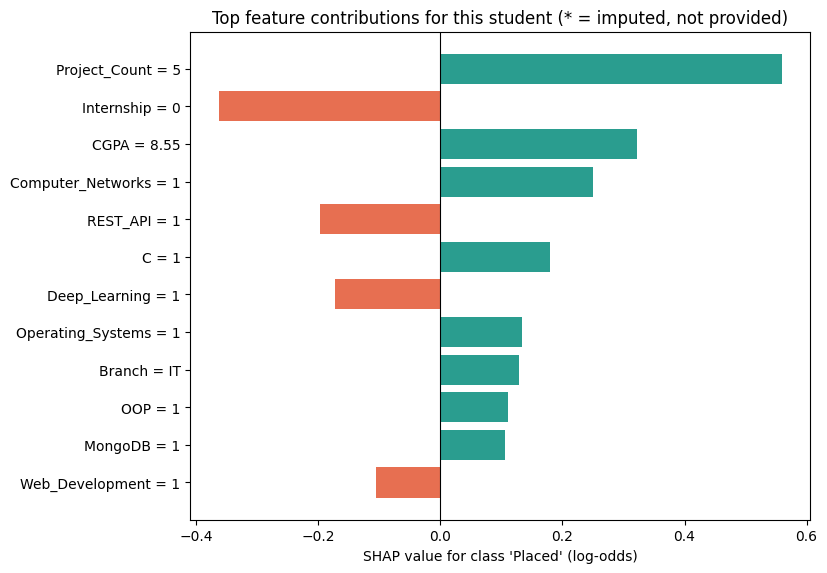

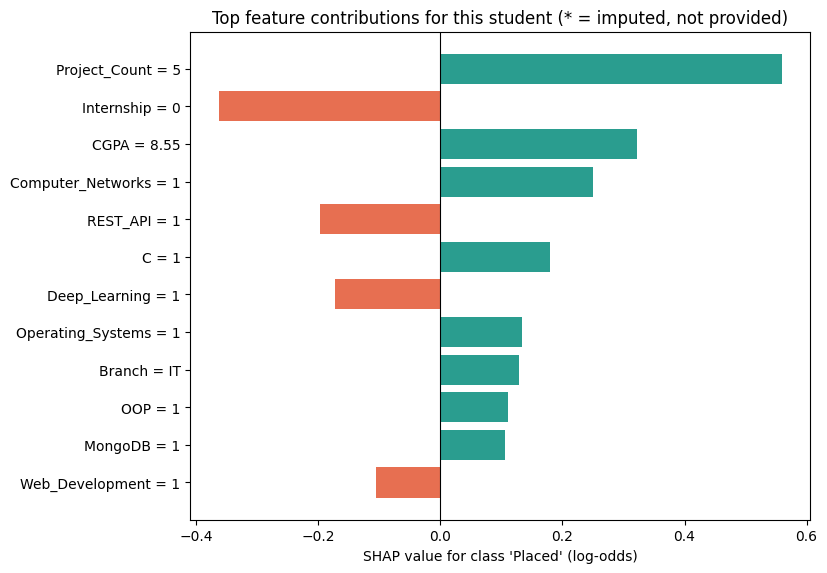

In [9]:
sx = ec.explain_prediction(model, pre, X_raw, background_df=df)
print("Additivity OK:", sx["additivity_ok"], "| explainer:", sx["explainer"])
print(ec.explanation_text(pred, sx))
ec.plot_shap_bar(sx)

In [18]:
import numpy as np
from IPython.display import Markdown, display
from skills_registry import SKILLS, display_name

# Only things a student cannot change (not advice, just exclusions)
FIXED = {"Year", "Branch", "UG_Degree", "PG_Specialization", "Education_Level",
         "PG_Required_For_Target_Role", "Relevant_Degree_Required"}

raw_cols = list(pre.feature_names_in_)
prof = ec.profile_dataset(df, raw_cols)

def nice(f):
    return display_name(f) if f in SKILLS else f.replace("_", " ").lower()

def isnan(v):
    return v is None or (isinstance(v, float) and np.isnan(v))

def fmt(v):
    return f"{v:g}" if isinstance(v, (float, np.floating)) else str(v)

def describe(f, v):
    """Sentence fragment about the student's own value, compared with the average student."""
    if isnan(v):
        return f"your {nice(f)} (not provided)"
    info = prof.get(f, {})
    if f in SKILLS or info.get("kind") == "binary":
        has = float(v) == 1
        share = df[f].mean() * 100 if f in df else None
        extra = f" ({share:.0f}% of students have it)" if share is not None else ""
        return (f"you have {nice(f)}" if has else f"you do not have {nice(f)}") + extra
    avg = df[f].mean() if f in df else None
    if avg is None:
        return f"your {nice(f)} is {fmt(v)}"
    rel = "above" if v > avg * 1.02 else "below" if v < avg * 0.98 else "close to"
    return f"your {nice(f)} is {fmt(v)}, {rel} the average of {avg:.1f}"

def size(a, m):
    r = a / m if m else 0
    return "a big" if r >= 0.66 else "a noticeable" if r >= 0.33 else "a small"

def what_if(feature):
    """Ask the model: if this one thing improved, what would the score become?"""
    if feature in FIXED or feature not in prof or prof[feature]["kind"] == "categorical":
        return None
    cur = X_raw.iloc[0][feature]
    if prof[feature]["kind"] == "binary":
        cands = [1.0, 0.0]
    else:
        cands = [df[feature].quantile(q) for q in (0.25, 0.5, 0.75, 0.9)]
    best = None
    for c in cands:
        if not isnan(cur) and abs(c - cur) < 1e-9:
            continue
        X2 = X_raw.copy()
        X2[feature] = c
        p2 = ec.predict_employability(model, pre, X2)["p_placed"]
        if p2 > pred["p_placed"] + 0.005 and (best is None or p2 > best[1]):
            best = (c, p2)
    return best

def student_friendly_explanation(pred, sx, top_n=4):
    t = sx["raw_table"]
    m = float(t["shap"].abs().max())
    pos = t[t["shap"] > 0].head(top_n)
    neg = t[t["shap"] < 0].sort_values("shap").head(top_n)
    p, base = pred["p_placed"], sx["base_probability"]
    diff = abs(p - base) * 100

    out = ["## 🎓 Your Employability Report",
           f"The model gives your profile a score of **{p:.0%}**. The average student scores about **{base:.0%}**, "
           f"so you are **{diff:.0f} points {'above' if p > base else 'below'}** average. "
           f"Below is *why* the model scored you this way."]

    out.append("### ✅ What is helping you")
    for _, r in pos.iterrows():
        out.append(f"- {describe(r['feature'], r['student_value']).capitalize()}. "
                   f"This gives {size(r['shap'], m)} boost to your score.")
    if pos.empty:
        out.append("- No factor is giving a clear boost yet.")

    out.append("### ⚠️ What is holding you back")
    for _, r in neg.iterrows():
        out.append(f"- {describe(r['feature'], r['student_value']).capitalize()}. "
                   f"This lowers your score by {size(abs(r['shap']), m)} amount.")
    if neg.empty:
        out.append("- Nothing is pulling your score down.")

    out.append("### 🚀 What could change your score")
    found = False
    for _, r in t[t["shap"] < 0].sort_values("shap").iterrows():
        res = what_if(r["feature"])
        if res:
            found = True
            c, p2 = res
            target = ("having it" if r["feature"] in SKILLS or prof[r["feature"]]["kind"] == "binary"
                      else f"reaching about {fmt(round(c, 1))}")
            out.append(f"- If you improved **{nice(r['feature'])}** ({target}), "
                       f"your score could go from **{p:.0%} to {p2:.0%}**.")
        if sum("could go from" in x for x in out) >= 3:
            break
    if not found:
        out.append("- No single change would raise your score much. Improving several areas together is the way forward.")

    n_imp = int(t["imputed"].sum())
    if n_imp:
        out.append(f"> 📝 {n_imp} details were not filled in, so typical values were used for them. "
                   "Fill in more details for a more accurate report.")
    out.append("> ℹ️ This is based on a practice dataset. It explains how the model sees your profile, "
               "not what will actually happen. Use it as a guide.")
    return "\n\n".join(out)

display(Markdown(student_friendly_explanation(pred, sx)))

## 🎓 Your Employability Report

The model gives your profile a score of **72%**. The average student scores about **47%**, so you are **25 points above** average. Below is *why* the model scored you this way.

### ✅ What is helping you

- Your project count is 5, above the average of 2.1. This gives a big boost to your score.

- Your cgpa is 8.55, above the average of 7.7. This gives a noticeable boost to your score.

- You have computer networks (6% of students have it). This gives a noticeable boost to your score.

- You have c (10% of students have it). This gives a small boost to your score.

### ⚠️ What is holding you back

- You do not have internship (34% of students have it). This lowers your score by a noticeable amount.

- You have rest apis (2% of students have it). This lowers your score by a noticeable amount.

- You have deep learning (6% of students have it). This lowers your score by a small amount.

- You have web development (26% of students have it). This lowers your score by a small amount.

### 🚀 What could change your score

- If you improved **internship** (having it), your score could go from **72% to 88%**.

- If you improved **REST APIs** (having it), your score could go from **72% to 76%**.

- If you improved **Deep Learning** (having it), your score could go from **72% to 75%**.

> 📝 125 details were not filled in, so typical values were used for them. Fill in more details for a more accurate report.

> ℹ️ This is based on a practice dataset. It explains how the model sees your profile, not what will actually happen. Use it as a guide.

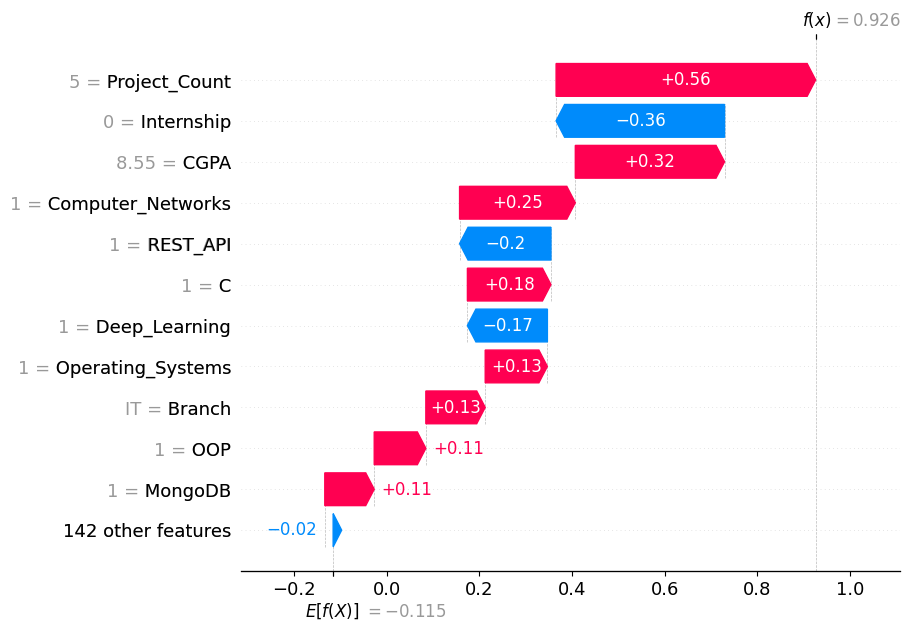

In [10]:
ec.plot_shap_waterfall(sx, X_raw)

## 9. (Optional) Validate the model on your dataset
Uses cross-validated *clones*; your saved artifacts are not modified.

In [11]:
if df is not None:
    res = ec.evaluate_model(df, model, pre)
    print(res["pair_check"]); print(res["calibration_status"])
    pprint.pprint(res["cross_validated"])
    res["figure"]

OK
Assessed on SYNTHETIC data by 5-fold CV of clones: Brier=0.210, log loss=0.610, ECE(10 bins)=0.059, ROC-AUC=0.734. Good synthetic-data calibration says nothing about real-world calibration.
{'accuracy': 0.6764,
 'brier': np.float64(0.20980682383968347),
 'confusion_matrix': [[1973, 899], [719, 1409]],
 'ece_10bin': 0.05941713924133834,
 'f1': 0.6352569882777277,
 'log_loss': 0.6102619835754165,
 'precision': 0.6104852686308492,
 'recall': 0.662124060150376,
 'roc_auc': np.float64(0.7342931885772928)}


---
# Part 2 — Skill-gap analysis for a target job role
Give a **target role** (for example *Data Scientist*, *Backend Developer*, *Cybersecurity Analyst*). The notebook then:
1. lists the **skills you already have** (from your resume, your confirmations in step 6, and anything you add by hand),
2. compares them with the **core and preferred skills** for that role,
3. shows your **gaps** and a **readiness score**,
4. gives a **step-by-step plan**: what to learn first, projects to build, certifications, profile fixes, resume tips and interview topics,
5. *(optional)* uses your saved model to show how its score would change if you added each missing skill.

**Run steps 1–5 first** (install, upload, `employability_core.py`, load artifacts, extract resume). Step 6 is recommended because it records your confirmed skills and profile values.

**How to read the results:** the role requirements come from the editable catalog inside `skill_gap.py` (17 roles). It is a hand-written reference, not live job-market data, so edit it to match the jobs you are targeting. The readiness score is the share of that role's skills found in your resume (core skills count double); it is a planning aid, not a hiring probability.

## 10. `skill_gap.py` (role catalog + gap analysis)
Supported roles: Data Analyst, Data Scientist, Machine Learning Engineer, Generative AI Engineer, Data Engineer, Software Developer, Backend Developer, Frontend Developer, Full Stack Developer, DevOps Engineer, Cloud Engineer, Cybersecurity Analyst, QA / Test Automation Engineer, Android Developer, Business Analyst, Embedded Systems Engineer, UI/UX Designer.

A role that is not listed can still be analysed: you will be asked to type the skills it needs.

In [12]:
%%writefile skill_gap.py
"""
skill_gap.py
============
Skill-gap analysis for a TARGET JOB ROLE, built on top of employability_core.

Flow:  target role  ->  skills the student HAS (resume + confirmations)
                    ->  required skills for the role (core / preferred)
                    ->  gap table, readiness score, learning plan, projects, certs
                    ->  (optional) what-if with the saved model.

Nothing here fits or retrains any model. The role catalog is a hand-written,
editable reference (ROLES / SKILL_DB below), not scraped live job-market data.
"""
import re
import difflib

import numpy as np
import pandas as pd

# =============================================================================
# 1. SKILL DATABASE   name -> (category, [aliases used to find it in resume text])
#    Aliases of length <= 2 (C, R, Go, C#) are matched case-sensitively.
# =============================================================================
SKILL_DB = {
    # Programming
    "Python": ("Programming", ["python", "python3"]),
    "Java": ("Programming", ["java", "core java"]),
    "C": ("Programming", ["C"]),
    "C++": ("Programming", ["C++", "cpp"]),
    "JavaScript": ("Programming", ["javascript", "js", "es6"]),
    "TypeScript": ("Programming", ["typescript"]),
    "SQL": ("Programming", ["sql", "t-sql", "pl/sql"]),
    "R": ("Programming", ["R", "rstudio"]),
    "Kotlin": ("Programming", ["kotlin"]),
    "Dart": ("Programming", ["dart"]),
    "Bash/Shell": ("Programming", ["bash", "shell scripting", "shell script", "shell"]),
    # Core CS
    "Data Structures & Algorithms": ("Core CS", ["data structures", "dsa", "algorithms", "data structures and algorithms"]),
    "OOP": ("Core CS", ["oop", "oops", "object oriented", "object-oriented"]),
    "Operating Systems": ("Core CS", ["operating systems", "operating system"]),
    "Computer Networks": ("Core CS", ["computer networks", "computer networking", "tcp/ip", "networking"]),
    "DBMS": ("Core CS", ["dbms", "database management"]),
    "System Design": ("Core CS", ["system design", "low level design", "high level design", "microservices"]),
    # Data & analytics
    "Excel": ("Data & Analytics", ["excel", "advanced excel", "pivot table", "pivot tables", "vlookup"]),
    "Statistics": ("Data & Analytics", ["statistics", "statistical analysis", "hypothesis testing", "probability"]),
    "Pandas": ("Data & Analytics", ["pandas"]),
    "NumPy": ("Data & Analytics", ["numpy"]),
    "Data Visualization": ("Data & Analytics", ["data visualization", "data visualisation", "matplotlib", "seaborn", "plotly"]),
    "Power BI": ("Data & Analytics", ["power bi", "powerbi"]),
    "Tableau": ("Data & Analytics", ["tableau"]),
    "ETL": ("Data & Analytics", ["etl", "elt", "data pipeline", "data pipelines"]),
    "Data Warehousing": ("Data & Analytics", ["data warehouse", "data warehousing", "snowflake", "redshift", "bigquery"]),
    "Apache Spark": ("Data & Analytics", ["spark", "pyspark", "apache spark"]),
    "Airflow": ("Data & Analytics", ["airflow", "apache airflow"]),
    "Kafka": ("Data & Analytics", ["kafka", "apache kafka"]),
    # AI / ML
    "Machine Learning": ("AI / ML", ["machine learning", "ml models", "supervised learning"]),
    "Scikit-learn": ("AI / ML", ["scikit-learn", "scikit learn", "sklearn"]),
    "Deep Learning": ("AI / ML", ["deep learning", "neural network", "neural networks", "cnn", "rnn", "lstm"]),
    "TensorFlow": ("AI / ML", ["tensorflow", "keras"]),
    "PyTorch": ("AI / ML", ["pytorch", "torch"]),
    "NLP": ("AI / ML", ["nlp", "natural language processing", "text mining", "bert", "spacy", "nltk"]),
    "Computer Vision": ("AI / ML", ["computer vision", "opencv", "image processing", "yolo"]),
    "Generative AI": ("AI / ML", ["generative ai", "genai", "llm", "llms", "large language model", "large language models", "rag"]),
    "Prompt Engineering": ("AI / ML", ["prompt engineering", "prompt design"]),
    "LangChain": ("AI / ML", ["langchain", "llamaindex", "llama index"]),
    "Vector Databases": ("AI / ML", ["vector database", "vector databases", "faiss", "pinecone", "chroma", "chromadb", "weaviate"]),
    "MLOps": ("AI / ML", ["mlops", "mlflow", "model deployment", "kubeflow"]),
    # Web & APIs
    "HTML": ("Web & APIs", ["html", "html5"]),
    "CSS": ("Web & APIs", ["css", "css3", "tailwind", "bootstrap", "sass"]),
    "React": ("Web & APIs", ["react", "reactjs", "react.js", "next.js", "nextjs"]),
    "Node.js": ("Web & APIs", ["node.js", "nodejs", "node js", "express", "express.js"]),
    "REST APIs": ("Web & APIs", ["rest api", "rest apis", "restful", "restful api", "restful apis", "api development", "graphql"]),
    "Django": ("Web & APIs", ["django"]),
    "Flask": ("Web & APIs", ["flask"]),
    "FastAPI": ("Web & APIs", ["fastapi"]),
    "Spring Boot": ("Web & APIs", ["spring boot", "springboot", "spring"]),
    "Responsive Design": ("Web & APIs", ["responsive design", "responsive web", "mobile-first", "media queries"]),
    # Databases
    "MySQL": ("Databases", ["mysql"]),
    "PostgreSQL": ("Databases", ["postgresql", "postgres"]),
    "MongoDB": ("Databases", ["mongodb", "mongo db", "nosql"]),
    "Database Design": ("Databases", ["database design", "schema design", "normalization", "normalisation", "er diagram", "er diagrams"]),
    # DevOps & cloud
    "Git": ("DevOps & Cloud", ["git", "github", "gitlab", "version control"]),
    "Linux": ("DevOps & Cloud", ["linux", "ubuntu", "unix"]),
    "Docker": ("DevOps & Cloud", ["docker", "containerization", "containerisation"]),
    "Kubernetes": ("DevOps & Cloud", ["kubernetes", "k8s", "helm"]),
    "CI/CD": ("DevOps & Cloud", ["ci/cd", "ci cd", "github actions", "gitlab ci", "continuous integration"]),
    "Jenkins": ("DevOps & Cloud", ["jenkins"]),
    "Terraform": ("DevOps & Cloud", ["terraform", "infrastructure as code"]),
    "Ansible": ("DevOps & Cloud", ["ansible"]),
    "AWS": ("DevOps & Cloud", ["aws", "amazon web services", "ec2", "s3", "lambda"]),
    "Azure": ("DevOps & Cloud", ["azure", "microsoft azure"]),
    "GCP": ("DevOps & Cloud", ["gcp", "google cloud"]),
    "Monitoring": ("DevOps & Cloud", ["prometheus", "grafana", "monitoring", "observability", "datadog"]),
    # Security
    "Network Security": ("Security", ["network security", "firewall", "firewalls", "ids/ips", "vpn"]),
    "Penetration Testing": ("Security", ["penetration testing", "pentesting", "pen testing", "ethical hacking", "metasploit", "burp suite"]),
    "Cryptography": ("Security", ["cryptography", "encryption", "pki"]),
    "SIEM": ("Security", ["siem", "splunk", "qradar", "soc analyst"]),
    "Vulnerability Assessment": ("Security", ["vulnerability assessment", "vulnerability scanning", "nessus", "openvas"]),
    "Incident Response": ("Security", ["incident response", "threat hunting", "digital forensics", "forensics"]),
    "OWASP": ("Security", ["owasp", "owasp top 10", "web application security"]),
    "Wireshark": ("Security", ["wireshark", "packet analysis"]),
    "Kali Linux": ("Security", ["kali linux", "kali"]),
    "Nmap": ("Security", ["nmap"]),
    # Testing & process
    "Manual Testing": ("Testing & Process", ["manual testing", "functional testing", "regression testing"]),
    "Test Case Design": ("Testing & Process", ["test case", "test cases", "test plan", "test scenarios", "bug report", "defect tracking"]),
    "Selenium": ("Testing & Process", ["selenium", "webdriver", "cypress", "playwright"]),
    "Test Automation": ("Testing & Process", ["test automation", "automation testing", "automated testing", "testng", "pytest"]),
    "API Testing": ("Testing & Process", ["api testing", "rest assured"]),
    "Postman": ("Testing & Process", ["postman"]),
    "JUnit": ("Testing & Process", ["junit", "unit testing", "unit tests"]),
    "SDLC": ("Testing & Process", ["sdlc", "software development life cycle", "stlc"]),
    "Agile/Scrum": ("Testing & Process", ["agile", "scrum", "kanban", "sprint"]),
    "JIRA": ("Testing & Process", ["jira", "confluence"]),
    # Mobile
    "Android": ("Mobile", ["android", "android studio", "android sdk"]),
    "Flutter": ("Mobile", ["flutter"]),
    "React Native": ("Mobile", ["react native"]),
    "Firebase": ("Mobile", ["firebase", "firestore"]),
    "Jetpack Compose": ("Mobile", ["jetpack compose", "compose ui"]),
    # Business analysis
    "Requirements Gathering": ("Business", ["requirements gathering", "requirement gathering", "requirements analysis", "brd", "frd", "user stories", "use cases"]),
    "UML": ("Business", ["uml", "use case diagram", "use case diagrams", "class diagram", "class diagrams", "bpmn"]),
    "Process Modeling": ("Business", ["process modeling", "process modelling", "process mapping", "workflow design", "visio"]),
    "Documentation": ("Business", ["documentation", "technical writing", "srs", "report writing"]),
    "Stakeholder Management": ("Business", ["stakeholder", "stakeholders", "client communication", "client interaction"]),
    # Embedded
    "Embedded C": ("Embedded", ["embedded c"]),
    "Microcontrollers": ("Embedded", ["microcontroller", "microcontrollers", "arduino", "stm32", "arm cortex", "8051", "esp32", "avr", "pic microcontroller"]),
    "RTOS": ("Embedded", ["rtos", "freertos", "real time operating system", "real-time operating system"]),
    "Communication Protocols": ("Embedded", ["i2c", "spi", "uart", "can bus", "modbus", "serial communication"]),
    "Circuit Design": ("Embedded", ["circuit design", "pcb design", "pcb", "schematic", "altium", "kicad", "proteus", "multisim"]),
    "Raspberry Pi": ("Embedded", ["raspberry pi"]),
    "IoT": ("Embedded", ["iot", "internet of things", "mqtt"]),
    # Design
    "Figma": ("Design", ["figma", "adobe xd", "sketch app"]),
    "Wireframing": ("Design", ["wireframe", "wireframes", "wireframing", "low fidelity", "mockups"]),
    "Prototyping": ("Design", ["prototyping", "prototype", "prototypes", "clickable prototype"]),
    "User Research": ("Design", ["user research", "usability testing", "user interviews", "personas", "persona", "ux research"]),
    "Design Systems": ("Design", ["design system", "design systems", "style guide", "component library"]),
}

# Rough weeks to reach "can use it in a small project" at ~8-10 hrs/week. Default = 3.
WEEKS = {
    "Python": 6, "Java": 8, "C": 6, "C++": 8, "JavaScript": 6, "TypeScript": 3, "SQL": 4, "R": 4, "Kotlin": 5,
    "Dart": 3, "Data Structures & Algorithms": 10, "OOP": 3, "Operating Systems": 5, "Computer Networks": 5,
    "DBMS": 4, "System Design": 6, "Statistics": 6, "Machine Learning": 8, "Deep Learning": 8, "NLP": 5,
    "Computer Vision": 5, "Generative AI": 4, "MLOps": 5, "React": 5, "Node.js": 4, "Django": 4,
    "Spring Boot": 5, "Kubernetes": 5, "Linux": 4, "AWS": 5, "Azure": 5, "GCP": 5, "Network Security": 6,
    "Penetration Testing": 6, "Cryptography": 4, "Android": 6, "Flutter": 5, "Embedded C": 5,
    "Microcontrollers": 4, "RTOS": 4, "Figma": 2, "Git": 1, "Postman": 1, "Excel": 2, "JIRA": 1, "Nmap": 1,
    "Wireshark": 1, "PyTorch": 5, "TensorFlow": 4, "Apache Spark": 4, "Kali Linux": 1, "HTML": 2, "CSS": 3, "Selenium": 3, "Docker": 2, "Tableau": 2, "Power BI": 3,
}

TIPS = {
    "Python": "Solve 50+ beginner-to-medium problems and build 2 small scripts/apps (HackerRank or LeetCode Easy tier is enough to start).",
    "SQL": "Practise joins, GROUP BY, window functions and subqueries on a real dataset; aim for 50+ queries.",
    "Data Structures & Algorithms": "Follow one structured list (arrays, strings, hashing, trees, graphs, DP) and solve a few problems every day; consistency beats volume.",
    "Statistics": "Cover descriptive stats, distributions, hypothesis testing and regression; apply each on a Kaggle or open dataset.",
    "Machine Learning": "Complete an introductory ML course, then reproduce a full workflow (cleaning, features, model, evaluation) on a Kaggle dataset.",
    "Git": "Use Git for every project from today; push to GitHub with clear commits and a README.",
    "Docker": "Containerise one of your existing projects and write a Dockerfile plus docker-compose file.",
    "REST APIs": "Build a CRUD API with authentication and test it in Postman; publish the docs.",
    "System Design": "Study the basics (load balancing, caching, databases, queues) and practise designing 5 common systems.",
    "Generative AI": "Build a small RAG chatbot over your own documents and document its limitations.",
    "Excel": "Learn pivot tables, lookups and charts by cleaning and summarising a public dataset.",
    "Power BI": "Build one end-to-end dashboard from a public dataset and publish a screenshot or link.",
}


def tip_for(skill):
    return TIPS.get(skill, f"Take one structured course on {skill}, then apply it in a small project and list the project on your resume.")


def weeks_for(skill):
    return WEEKS.get(skill, 3)


# =============================================================================
# 2. ROLE CATALOG (editable). Entries in core/preferred may be a tuple = "any one of".
# =============================================================================
ROLES = {
    "Data Analyst": dict(
        aliases=["data analytics", "business intelligence analyst", "bi analyst", "reporting analyst", "analyst"],
        core=["SQL", "Excel", "Statistics", "Data Visualization", "Python", "Power BI"],
        preferred=["Tableau", "Pandas", "NumPy", "ETL", "R"],
        min_projects=2,
        certifications=["Google Data Analytics Certificate", "Microsoft PL-300 (Power BI Data Analyst)", "Tableau Desktop Specialist"],
        projects=[("Sales or HR dashboard with KPIs, filters and a written insight summary", ["Power BI", "SQL", "Excel", "Data Visualization"]),
                  ("Exploratory data analysis of a public dataset with a clear business recommendation", ["Python", "Pandas", "Statistics", "Data Visualization"]),
                  ("SQL case study: answer 15 business questions on a sample database", ["SQL"]),
                  ("Tableau story on a public-health or finance dataset", ["Tableau", "Data Visualization"])],
        interview=["SQL joins and window functions", "A/B testing and hypothesis testing basics", "Explaining a dashboard to a non-technical person", "Excel pivot tables and lookups"]),
    "Data Scientist": dict(
        aliases=["data science", "ds", "applied scientist", "junior data scientist"],
        core=["Python", "Statistics", "Machine Learning", "Pandas", "NumPy", "Scikit-learn", "SQL", "Data Visualization"],
        preferred=["Deep Learning", "PyTorch", "TensorFlow", "NLP", "Apache Spark", "Git", "AWS"],
        min_projects=3,
        certifications=["DeepLearning.AI Machine Learning Specialization (Coursera)", "IBM Data Science Professional Certificate", "Microsoft DP-100 (Azure Data Scientist)"],
        projects=[("End-to-end prediction project (churn, price or risk) with proper train/test split and error analysis", ["Python", "Pandas", "Scikit-learn", "Machine Learning", "Statistics"]),
                  ("Kaggle competition entry with feature engineering and a written write-up", ["Python", "Machine Learning", "Pandas", "NumPy"]),
                  ("NLP sentiment or topic analysis on a real text dataset", ["NLP", "Python", "Deep Learning"]),
                  ("Deploy a trained model behind a simple web app", ["Python", "Machine Learning", "Git"])],
        interview=["Bias-variance, overfitting and regularisation", "Evaluation metrics (precision/recall/ROC-AUC) and when to use them", "SQL and pandas data manipulation", "Walking through one of your projects end to end"]),
    "Machine Learning Engineer": dict(
        aliases=["ml", "ml engineer", "mle", "ai ml engineer", "ai/ml engineer", "artificial intelligence engineer", "ai engineer"],
        core=["Python", "Machine Learning", "Deep Learning", "Scikit-learn", "PyTorch", "Data Structures & Algorithms", "Git", "Docker"],
        preferred=["TensorFlow", "MLOps", "FastAPI", "Kubernetes", "AWS", "Apache Spark", "SQL"],
        min_projects=3,
        certifications=["DeepLearning.AI Deep Learning Specialization", "AWS Certified Machine Learning Engineer - Associate", "Google Cloud Professional ML Engineer (later stage)"],
        projects=[("Train a deep learning model and serve it as a containerised API", ["PyTorch", "Deep Learning", "Docker", "FastAPI"]),
                  ("Reproduce a paper or a Kaggle solution and compare against a baseline", ["Python", "Machine Learning", "Scikit-learn"]),
                  ("Experiment tracking and model versioning pipeline", ["MLOps", "Git", "Python"]),
                  ("Image or text classifier with a monitored prediction endpoint", ["Deep Learning", "Docker", "AWS"])],
        interview=["Coding rounds on arrays, strings and hashing", "How backpropagation and gradient descent work", "Model deployment and monitoring trade-offs", "Debugging an underperforming model"]),
    "Generative AI Engineer": dict(
        aliases=["gen ai engineer", "genai engineer", "llm engineer", "generative ai developer", "ai application developer", "prompt engineer"],
        core=["Python", "Generative AI", "Prompt Engineering", "LangChain", "Vector Databases", "NLP", "REST APIs", "FastAPI"],
        preferred=["PyTorch", "Deep Learning", "Docker", "Git", "MLOps", "AWS"],
        min_projects=3,
        certifications=["DeepLearning.AI short courses on LLMs, RAG and agents", "Microsoft AI-102 (Azure AI Engineer Associate)", "Cloud provider AI fundamentals (AWS / Azure / Google Cloud)"],
        projects=[("RAG question-answering bot over your own PDFs with source citations", ["Generative AI", "LangChain", "Vector Databases", "Python"]),
                  ("LLM-powered API service with prompt versioning and basic evaluation", ["FastAPI", "REST APIs", "Prompt Engineering"]),
                  ("Text summariser or classifier comparing a fine-tuned model with prompting", ["NLP", "PyTorch", "Deep Learning"]),
                  ("Containerised chatbot deployed to a cloud free tier", ["Docker", "AWS", "Git"])],
        interview=["How RAG works and where it fails", "Prompt design and evaluation methods", "Embeddings and vector search basics", "API design and latency/cost trade-offs"]),
    "Data Engineer": dict(
        aliases=["big data engineer", "etl developer", "data pipeline engineer", "analytics engineer"],
        core=["SQL", "Python", "ETL", "Data Warehousing", "Apache Spark", "Airflow", "Linux", "Git"],
        preferred=["Kafka", "AWS", "Docker", "PostgreSQL", "Kubernetes", "Azure"],
        min_projects=3,
        certifications=["Databricks Certified Data Engineer Associate", "Google Professional Data Engineer (later stage)", "Microsoft DP-700 (Fabric Data Engineer Associate)"],
        projects=[("Batch ETL pipeline from an API into a warehouse, scheduled with Airflow", ["ETL", "Airflow", "Python", "SQL", "Data Warehousing"]),
                  ("PySpark job processing a multi-GB public dataset", ["Apache Spark", "Python"]),
                  ("Streaming pipeline with Kafka and a simple dashboard", ["Kafka", "Python"]),
                  ("Dockerised data pipeline with tests and README", ["Docker", "Git", "Linux"])],
        interview=["Advanced SQL (windows, CTEs, query tuning)", "Star schema and data modelling", "Batch vs streaming trade-offs", "Spark partitioning and shuffles"]),
    "Software Developer": dict(
        aliases=["software engineer", "sde", "sde 1", "software development engineer", "programmer", "application developer", "software developer trainee", "associate software engineer"],
        core=["Data Structures & Algorithms", "OOP", ("Java", "Python", "C++"), "SQL", "DBMS", "Operating Systems", "Git"],
        preferred=["System Design", "Computer Networks", "REST APIs", "Docker", "Linux"],
        min_projects=2,
        certifications=["NPTEL Data Structures and Algorithms", "Oracle Java SE Programmer (if Java-focused)", "Cloud fundamentals (AWS Cloud Practitioner or Azure AZ-900)"],
        projects=[("Full application with login, CRUD and a database (for example a library or expense manager)", ["OOP", "SQL", "DBMS", "Git"]),
                  ("Implement core data structures from scratch with unit tests", ["Data Structures & Algorithms", "OOP"]),
                  ("Multi-threaded or file-system based tool that exercises OS concepts", ["Operating Systems", "OOP"]),
                  ("REST service containerised with Docker", ["REST APIs", "Docker", "Git"])],
        interview=["Arrays, strings, hashing, trees, graphs, DP", "OOP principles and SOLID", "DBMS normalisation, transactions and indexing", "OS: processes, threads, deadlocks, memory"]),
    "Backend Developer": dict(
        aliases=["backend engineer", "back end developer", "server side developer", "java developer", "python developer", "api developer", "node developer"],
        core=[("Java", "Python", "Node.js"), "Data Structures & Algorithms", "OOP", "REST APIs", "SQL", "Database Design", "Git"],
        preferred=["Spring Boot", "Django", "MongoDB", "Docker", "System Design", "AWS", "Operating Systems"],
        min_projects=3,
        certifications=["Oracle Java SE Programmer (Java track)", "AWS Cloud Practitioner / Solutions Architect Associate", "NPTEL Database Management Systems"],
        projects=[("REST API with JWT authentication, pagination, validation and tests", ["REST APIs", "SQL", "Database Design", "Git"]),
                  ("E-commerce or booking backend with relational schema and transactions", ["Database Design", "SQL", "Spring Boot", "Django"]),
                  ("Rate-limited or cached API using Redis-style caching concepts", ["System Design", "REST APIs"]),
                  ("Dockerised service deployed on a cloud free tier", ["Docker", "AWS", "Git"])],
        interview=["REST design and HTTP status codes", "SQL joins, indexes and transactions", "Authentication and authorisation flows", "Designing a URL shortener or similar small system"]),
    "Frontend Developer": dict(
        aliases=["front end developer", "front-end developer", "ui developer", "web developer", "react developer", "javascript developer"],
        core=["HTML", "CSS", "JavaScript", "React", "Responsive Design", "Git", "REST APIs"],
        preferred=["TypeScript", "Figma", "Node.js"],
        min_projects=3,
        certifications=["Meta Front-End Developer Professional Certificate (Coursera)", "freeCodeCamp Responsive Web Design / JavaScript certifications"],
        projects=[("Responsive portfolio site deployed on GitHub Pages or Netlify", ["HTML", "CSS", "Responsive Design", "Git"]),
                  ("React app that consumes a public API with loading and error states", ["React", "JavaScript", "REST APIs"]),
                  ("Clone of a real product page or dashboard with reusable components", ["React", "CSS"]),
                  ("Convert a Figma design to pixel-accurate code", ["Figma", "HTML", "CSS"])],
        interview=["JavaScript closures, promises and the event loop", "React hooks and state management", "CSS layout (flexbox/grid) and accessibility", "Browser rendering and performance basics"]),
    "Full Stack Developer": dict(
        aliases=["fullstack developer", "full-stack developer", "mern developer", "mean developer", "full stack engineer"],
        core=["HTML", "CSS", "JavaScript", "React", "Node.js", "REST APIs", ("SQL", "MongoDB"), "Git"],
        preferred=["TypeScript", "Docker", "AWS", "System Design", "Django"],
        min_projects=3,
        certifications=["freeCodeCamp Full Stack certifications", "Meta Full-Stack or Back-End Developer certificates (Coursera)", "AWS Cloud Practitioner"],
        projects=[("Full-stack app with auth, CRUD and a database, deployed publicly", ["React", "Node.js", "REST APIs", "MongoDB", "SQL"]),
                  ("Real-time chat or collaborative tool", ["Node.js", "JavaScript", "React"]),
                  ("Dockerised app with CI pipeline", ["Docker", "Git", "AWS"]),
                  ("Admin dashboard with role-based access", ["React", "REST APIs", "CSS"])],
        interview=["End-to-end request flow from browser to database", "JavaScript and React fundamentals", "SQL vs NoSQL choices", "Securing an API (auth, CORS, validation)"]),
    "DevOps Engineer": dict(
        aliases=["devops", "site reliability engineer", "sre", "build and release engineer", "platform engineer"],
        core=["Linux", "Bash/Shell", "Git", "Docker", "CI/CD", ("AWS", "Azure", "GCP"), "Kubernetes"],
        preferred=["Terraform", "Ansible", "Jenkins", "Monitoring", "Python", "Computer Networks"],
        min_projects=3,
        certifications=["AWS Cloud Practitioner then Solutions Architect Associate", "Certified Kubernetes Application Developer (CKAD)", "HashiCorp Terraform Associate"],
        projects=[("CI/CD pipeline that builds, tests and deploys a containerised app", ["CI/CD", "Docker", "Git", "Jenkins"]),
                  ("Deploy an app to Kubernetes (minikube or kind) with health checks", ["Kubernetes", "Docker"]),
                  ("Provision cloud infrastructure with Terraform", ["Terraform", "AWS", "Azure", "GCP"]),
                  ("Monitoring dashboard with alerts for a sample service", ["Monitoring", "Linux"])],
        interview=["Linux troubleshooting (processes, disk, networking)", "Docker image layers and networking", "CI/CD stages and rollback strategies", "Kubernetes pods, services and deployments"]),
    "Cloud Engineer": dict(
        aliases=["cloud architect", "cloud administrator", "cloud support engineer", "aws engineer", "azure engineer", "cloud developer"],
        core=[("AWS", "Azure", "GCP"), "Linux", "Computer Networks", "Docker", "Git", "Bash/Shell"],
        preferred=["Terraform", "Kubernetes", "CI/CD", "Python", "Monitoring", "Network Security"],
        min_projects=2,
        certifications=["AWS Cloud Practitioner -> Solutions Architect Associate", "Microsoft AZ-900 -> AZ-104", "Google Associate Cloud Engineer"],
        projects=[("Three-tier web app hosted on a cloud provider with a load balancer", ["AWS", "Azure", "GCP", "Computer Networks", "Linux"]),
                  ("Infrastructure as code for a VPC plus compute and storage", ["Terraform", "Computer Networks"]),
                  ("Serverless API with logging and alerts", ["AWS", "Monitoring", "Python"]),
                  ("Containerised app deployed to a managed container service", ["Docker", "Kubernetes", "CI/CD"])],
        interview=["Shared-responsibility model and IAM basics", "VPC, subnets, routing and security groups", "Storage, compute and cost trade-offs", "High availability and backup design"]),
    "Cybersecurity Analyst": dict(
        aliases=["cyber security analyst", "security analyst", "soc analyst", "information security analyst", "cybersecurity engineer", "ethical hacker", "penetration tester", "infosec"],
        core=["Network Security", "Computer Networks", "Linux", "Cryptography", "Vulnerability Assessment", "Incident Response"],
        preferred=["Penetration Testing", "OWASP", "SIEM", "Wireshark", "Kali Linux", "Nmap", "Python"],
        min_projects=2,
        certifications=["CompTIA Security+", "ISC2 Certified in Cybersecurity (CC)", "Google Cybersecurity Certificate", "CEH (later stage)"],
        projects=[("Home lab: scan, find and report vulnerabilities on an intentionally vulnerable VM", ["Vulnerability Assessment", "Nmap", "Kali Linux", "Penetration Testing"]),
                  ("Packet-capture analysis report of suspicious traffic", ["Wireshark", "Computer Networks", "Network Security"]),
                  ("Log analysis and alerting rules in a SIEM (free tier or open-source)", ["SIEM", "Incident Response", "Linux"]),
                  ("OWASP Top 10 walkthrough on a practice web app", ["OWASP", "Penetration Testing"])],
        interview=["TCP/IP, DNS, HTTP and common attacks", "CIA triad, encryption and hashing", "Walking through an incident-response lifecycle", "OWASP Top 10 examples"]),
    "QA / Test Automation Engineer": dict(
        aliases=["qa", "qa engineer", "quality assurance engineer", "software tester", "test engineer", "automation tester", "sdet", "qa analyst", "tester", "testing engineer"],
        core=["Manual Testing", "Test Case Design", "SDLC", "Agile/Scrum", "Selenium", ("Java", "Python"), "SQL"],
        preferred=["Test Automation", "Postman", "API Testing", "JUnit", "CI/CD", "Git", "JIRA"],
        min_projects=2,
        certifications=["ISTQB Foundation Level (CTFL)", "Selenium / Playwright course certificates", "Postman API fundamentals"],
        projects=[("Selenium framework with page-object model and HTML reports", ["Selenium", "Test Automation", "Java", "Python"]),
                  ("Full test plan, test cases and bug reports for a public web app", ["Test Case Design", "Manual Testing", "SDLC"]),
                  ("Postman collection with automated API tests", ["Postman", "API Testing"]),
                  ("CI job that runs the automation suite on every commit", ["CI/CD", "Git", "JUnit"])],
        interview=["Test-case design techniques (boundary values, equivalence classes)", "Bug life cycle and severity vs priority", "Locators, waits and flaky-test handling", "Basic SQL checks for data validation"]),
    "Android Developer": dict(
        aliases=["android app developer", "mobile developer", "mobile app developer", "kotlin developer", "android engineer"],
        core=[("Kotlin", "Java"), "Android", "OOP", "REST APIs", "Git", "Data Structures & Algorithms"],
        preferred=["Jetpack Compose", "Firebase", "SQL", "Flutter", "React Native"],
        min_projects=3,
        certifications=["Google's Android developer training courses (developer.android.com)", "Kotlin fundamentals course certificates"],
        projects=[("Notes or expense tracker with local database and clean architecture", ["Android", "Kotlin", "SQL", "OOP"]),
                  ("App consuming a public REST API with pagination and caching", ["REST APIs", "Android"]),
                  ("Chat or to-do app with Firebase authentication and sync", ["Firebase", "Android"]),
                  ("Rebuild one screen set in Jetpack Compose", ["Jetpack Compose", "Kotlin"])],
        interview=["Activity/fragment lifecycle", "Kotlin coroutines and null safety", "MVVM architecture", "Handling network calls and offline data"]),
    "Business Analyst": dict(
        aliases=["ba", "business systems analyst", "functional analyst", "product analyst", "associate business analyst", "it business analyst"],
        core=["Requirements Gathering", "SQL", "Excel", "Documentation", "Agile/Scrum", "Stakeholder Management"],
        preferred=["Power BI", "Tableau", "UML", "Process Modeling", "JIRA", "Statistics"],
        min_projects=2,
        certifications=["IIBA ECBA", "Scrum Master / Product Owner fundamentals (PSM I, CSPO)", "Microsoft PL-300 (Power BI)"],
        projects=[("Write a BRD and user stories for a real app idea, with acceptance criteria", ["Requirements Gathering", "Documentation", "Agile/Scrum"]),
                  ("Process-flow and gap analysis of an existing workflow (for example college admissions)", ["Process Modeling", "UML", "Stakeholder Management"]),
                  ("KPI dashboard answering 5 business questions from a dataset", ["Power BI", "SQL", "Excel"]),
                  ("Sprint plan and backlog in JIRA for a team project", ["JIRA", "Agile/Scrum"])],
        interview=["Requirements elicitation techniques", "User stories vs use cases", "SQL queries for business questions", "Handling conflicting stakeholder priorities"]),
    "Embedded Systems Engineer": dict(
        aliases=["embedded engineer", "firmware engineer", "embedded software engineer", "embedded developer", "iot engineer", "embedded"],
        core=[("Embedded C", "C"), "Microcontrollers", "Communication Protocols", "RTOS", "Circuit Design"],
        preferred=["C++", "Raspberry Pi", "IoT", "Python", "Git", "Linux"],
        min_projects=3,
        certifications=["NPTEL Embedded Systems courses", "Vendor trainings (STMicroelectronics, Arm, Espressif)"],
        projects=[("Sensor data logger on a microcontroller using I2C/SPI and UART output", ["Microcontrollers", "Communication Protocols", "Embedded C"]),
                  ("FreeRTOS multi-task application (for example sensor + display + alarm)", ["RTOS", "Embedded C", "C"]),
                  ("IoT node publishing data over MQTT to a dashboard", ["IoT", "Raspberry Pi", "Python"]),
                  ("Custom PCB or breadboard schematic with documentation", ["Circuit Design"])],
        interview=["Pointers, bit manipulation, volatile and memory layout in C", "Interrupts, timers and ISR rules", "I2C vs SPI vs UART", "RTOS tasks, semaphores and priority inversion"]),
    "UI/UX Designer": dict(
        aliases=["ux", "ui", "ux designer", "ui designer", "product designer", "ui ux designer", "user experience designer", "interaction designer"],
        core=["Figma", "Wireframing", "Prototyping", "User Research", "Design Systems"],
        preferred=["HTML", "CSS", "Responsive Design"],
        min_projects=3,
        certifications=["Google UX Design Certificate", "Interaction Design Foundation courses"],
        projects=[("Case study: research, personas, wireframes and tested prototype for one app", ["User Research", "Wireframing", "Prototyping", "Figma"]),
                  ("Redesign an existing app screen set with before/after reasoning", ["Figma", "Design Systems"]),
                  ("Reusable component library and style guide", ["Design Systems", "Figma"]),
                  ("Responsive landing page designed and coded", ["HTML", "CSS", "Responsive Design"])],
        interview=["Portfolio walkthrough: problem, process, outcome", "Usability heuristics and accessibility", "How you validate a design decision", "Design critique and handling feedback"]),
}

GENERAL_SOFT_SKILL_ADVICE = (
    "Communication and teamwork are assessed in almost every interview: practise explaining one project in 2 minutes, "
    "prepare 3 STAR-format stories (challenge, action, result), and join a group project, club or hackathon to show collaboration."
)


# =============================================================================
# 3. SKILL DETECTION (local, alias based)
# =============================================================================
def _alias_rx(alias):
    toks = [re.escape(t) for t in alias.split()]
    body = r"[\s\-]+".join(toks)
    flags = 0 if len(alias) <= 2 else re.I
    return re.compile(rf"(?<![A-Za-z0-9+#]){body}(?![A-Za-z0-9+#])", flags)


_RX_CACHE = {}


def _patterns(skill):
    if skill not in _RX_CACHE:
        aliases = [skill] + SKILL_DB.get(skill, ("", []))[1]
        _RX_CACHE[skill] = [(a, _alias_rx(a)) for a in dict.fromkeys(aliases)]
    return _RX_CACHE[skill]


def detect_local(text, skills=None):
    """{skill: [matched strings]} for every catalog skill found in text."""
    out = {}
    for s in (skills or SKILL_DB):
        ev = []
        for _, rx in _patterns(s):
            for m in rx.finditer(text or ""):
                if m.group(0) not in ev and len(ev) < 3:
                    ev.append(m.group(0))
        if ev:
            out[s] = ev
    return out


def registry_key(skill, ec):
    """Map a catalog skill to the model-registry key (or None) using employability_core's alias table."""
    reg = getattr(ec, "_EXACT", None) or {}
    name = skill.strip().lower()
    k = reg.get(name)
    if not k:
        return None
    # accept only if the registry key/display IS this skill (an alias such as mysql -> SQL must not count)
    disp = str((getattr(ec, "SKILLS", {}).get(k, {}) or {}).get("display", k)).strip().lower()
    return k if name in (disp, str(k).lower()) else None


def collect_skills(resume_text="", ex=None, profile=None, manual=(), not_have=(), ec=None):
    """
    The student's skills, with evidence. Sources: resume text, the extractor output, ticks in the
    StudentProfile (present/absent), and skills typed by hand. `not_have` removes false positives.
    """
    ex = ex or {}
    corpus = "\n".join([resume_text or "",
                        " , ".join(map(str, ex.get("technical_skills", []))),
                        ex.get("project_section", ""), ex.get("internship_section", ""), ex.get("certification_section", "")])
    have = {s: dict(source="resume text", evidence=ev) for s, ev in detect_local(corpus).items()}

    if ec is not None:
        detected_keys = set(ex.get("skill_detections", {}) or {})
        present = profile.present_skills() if profile is not None else set()
        absent = ({k for k, v in profile.skill_state.items() if v == "absent"} if profile is not None else set())
        for s in SKILL_DB:
            k = registry_key(s, ec)
            if not k:
                continue
            if k in present:
                have.setdefault(s, dict(source="confirmed in profile", evidence=[s]))
            elif k in detected_keys:
                have.setdefault(s, dict(source="resume extractor", evidence=[s]))
            if k in absent and s in have and have[s]["source"] != "confirmed in profile":
                del have[s]
    for s in manual:
        s = _canonical(s)
        have[s] = dict(source="added by you", evidence=[s])
    for s in not_have:
        have.pop(_canonical(s), None)
    return have


def _canonical(name):
    n = str(name).strip()
    for s in SKILL_DB:
        if s.lower() == n.lower():
            return s
    low = n.lower()
    for s, (_, aliases) in SKILL_DB.items():
        if low in [a.lower() for a in aliases]:
            return s
    return n


def skill_inventory(have, ex=None):
    """Group the skills the student has by category (catalog skills + extra names from the extractor)."""
    groups = {}
    for s in sorted(have):
        groups.setdefault(SKILL_DB.get(s, ("Other", []))[0], []).append(s)
    known = {s.lower() for s in have}
    extra = [n for n in (ex or {}).get("technical_skills", []) if str(n).lower() not in known and _canonical(n) not in have]
    if extra:
        groups.setdefault("Other (from resume extractor)", []).extend(sorted(set(map(str, extra))))
    return groups


# =============================================================================
# 4. ROLE RESOLUTION
# =============================================================================
def _norm(s):
    return re.sub(r"[^a-z0-9+# ]+", " ", str(s).lower()).split()


def list_roles():
    return sorted(ROLES)


def resolve_role(query, top=3):
    """Ranked [(role, score)] for free text such as 'ml engg', 'sde', 'react developer'."""
    q = " ".join(_norm(query))
    if not q:
        return []
    scores = {}
    for role, r in ROLES.items():
        best = 0.0
        for name in [role] + r["aliases"]:
            n = " ".join(_norm(name))
            if q == n:
                best = 1.0
                break
            if min(len(q), len(n)) >= 4 and (n in q or q in n):
                best = max(best, 0.9)
            best = max(best, difflib.SequenceMatcher(None, q, n).ratio())
            qt, nt = set(q.split()), set(n.split())
            if qt and nt:
                best = max(best, 0.85 * len(qt & nt) / len(qt | nt))
        scores[role] = best
    ranked = sorted(scores.items(), key=lambda kv: -kv[1])
    return [(r, round(s, 2)) for r, s in ranked[:top] if s >= 0.45]


def choose_role(query, interactive=True):
    """
    Returns (role_name, role_dict). Asks a short question when the text is ambiguous or unknown.
    Unknown roles can be defined on the spot by typing the skills they need.
    """
    cands = resolve_role(query)
    if cands and (cands[0][1] == 1.0 or len(cands) == 1 or cands[0][1] - cands[1][1] >= 0.1):
        return cands[0][0], ROLES[cands[0][0]]
    if not interactive:
        if cands:
            print(f"Ambiguous role '{query}'; using best match '{cands[0][0]}'. Other options: {[c[0] for c in cands[1:]]}")
            return cands[0][0], ROLES[cands[0][0]]
        raise ValueError(f"Role '{query}' is not in the catalog. Supported roles: {list_roles()}. "
                         "Use custom_role(name, core_skills) to define it.")
    if cands:
        print(f"'{query}' could mean several roles:")
        for i, (r, s) in enumerate(cands, 1):
            print(f"  {i}. {r}")
        print("  0. None of these (define my own role)")
        pick = input("Choose a number: ").strip()
        if pick.isdigit() and 1 <= int(pick) <= len(cands):
            return cands[int(pick) - 1][0], ROLES[cands[int(pick) - 1][0]]
    else:
        print(f"'{query}' is not in the built-in catalog. Built-in roles: {', '.join(list_roles())}")
    raw = input(f"Type the skills a '{query}' needs, comma-separated (or press Enter to stop): ").strip()
    if not raw:
        raise ValueError("No role selected.")
    return query.strip().title(), custom_role(query, [s.strip() for s in raw.split(",") if s.strip()])


def custom_role(name, core, preferred=(), min_projects=2):
    """Define your own role. Unknown skills are registered so they can be matched in resume text."""
    for s in list(core) + list(preferred):
        for x in (s if isinstance(s, (tuple, list)) else [s]):
            if _canonical(x) not in SKILL_DB:
                SKILL_DB[_canonical(x)] = ("Custom", [])
    fix = lambda items: [tuple(_canonical(x) for x in i) if isinstance(i, (tuple, list)) else _canonical(i) for i in items]
    return dict(aliases=[], core=fix(core), preferred=fix(preferred), min_projects=min_projects,
                certifications=[], projects=[], interview=[], custom=True)


# =============================================================================
# 5. GAP ANALYSIS
# =============================================================================
def _groups(items):
    return [tuple(i) if isinstance(i, (tuple, list)) else (i,) for i in items]


def analyze_gap(role, have):
    rows = []
    for importance, items, weight in (("Core", role["core"], 2), ("Preferred", role["preferred"], 1)):
        for g in _groups(items):
            hit = [s for s in g if s in have]
            if hit:
                suggest, weeks = None, 0
            else:
                suggest = min(g, key=lambda s: (weeks_for(s), g.index(s)))
                weeks = weeks_for(suggest)
            rows.append(dict(requirement=" / ".join(g), importance=importance, status="Have" if hit else "Missing",
                             matched=", ".join(hit), evidence=", ".join(have[hit[0]]["evidence"]) if hit else "",
                             learn_first=suggest, est_weeks=weeks, weight=weight))
    t = pd.DataFrame(rows)
    pct = lambda d: round(100 * (d["status"] == "Have").mean(), 1) if len(d) else None
    core_t, pref_t = t[t.importance == "Core"], t[t.importance == "Preferred"]
    score = round(100 * (t.weight * (t.status == "Have")).sum() / t.weight.sum(), 1)
    label = ("Strong match: ready to apply, focus on projects and interview prep" if score >= 75 else
             "Good foundation: a few gaps to close before applying widely" if score >= 50 else
             "Early stage: build core skills first (see the plan below)" if score >= 25 else
             "Beginner for this role: start with the fundamentals in the plan below")
    return dict(table=t, score=score, label=label, core_pct=pct(core_t), preferred_pct=pct(pref_t),
                missing_core=core_t[core_t.status == "Missing"], missing_preferred=pref_t[pref_t.status == "Missing"],
                have_rows=t[t.status == "Have"])


# =============================================================================
# 6. RECOMMENDATIONS
# =============================================================================
def build_recommendations(role_name, role, gap, profile_values=None, ex=None):
    pv = profile_values or {}
    ex = ex or {}
    recs = {}

    plan, mc, mp = [], gap["missing_core"], gap["missing_preferred"]
    ordered = list(mc.itertuples()) + list(mp.itertuples())
    phase = lambda i, r: ("Phase 1 (now)" if r.importance == "Core" and i < 3 else
                          "Phase 2" if r.importance == "Core" else "Phase 3 (differentiators)")
    for i, r in enumerate(ordered):
        plan.append(dict(phase=phase(i, r), skill=r.learn_first, requirement=r.requirement, importance=r.importance,
                         est_weeks=r.est_weeks, how=tip_for(r.learn_first)))
    recs["learning_plan"] = pd.DataFrame(plan, columns=["phase", "skill", "requirement", "importance", "est_weeks", "how"])
    recs["core_weeks"] = int(mc["est_weeks"].sum()) if len(mc) else 0
    recs["preferred_weeks"] = int(mp["est_weeks"].sum()) if len(mp) else 0

    missing_names = {r.learn_first for r in ordered}
    scored = sorted(role.get("projects", []), key=lambda p: -len(missing_names & set(p[1])))
    recs["projects"] = [dict(title=t, covers=sorted(missing_names & set(sk))) for t, sk in scored[:3]]
    recs["certifications"] = role.get("certifications", [])
    recs["interview_topics"] = role.get("interview", [])

    prof = []
    projects, rel_projects = pv.get("Project_Count"), pv.get("Relevant_Project_Count")
    if projects is None:
        projects = ex.get("project_count_estimate")
    need = role.get("min_projects", 2)
    if projects is not None and projects < need:
        prof.append(f"Projects: you list {int(projects)}; for {role_name} aim for at least {need}, with the newest ones using the missing core skills.")
    if rel_projects is not None and rel_projects < 1:
        prof.append(f"None of your projects is marked relevant to {role_name}: build or reframe one so it clearly targets this role.")
    if pv.get("Internship") == 0:
        prof.append("No internship: apply for internships or virtual internships, or contribute to an open-source project, and document the outcome.")
    certs = pv.get("Certification_Count")
    if certs is None:
        certs = ex.get("certification_count_estimate")
    if certs is not None and certs < 1 and role.get("certifications"):
        prof.append("No certification listed: one recognised, role-relevant certificate (see list) shows initiative.")
    if pv.get("Backlogs") not in (None, 0):
        prof.append("Backlogs: clear them as early as possible; many recruiters require zero active backlogs.")
    cg = pv.get("CGPA")
    if cg is not None and cg < 6.5:
        prof.append("CGPA is on the lower side: some recruiters apply eligibility cut-offs, so offset it with strong projects, certifications and a clear portfolio.")
    if not ex.get("hackathon_mention", True):
        prof.append("No hackathon or competition mentioned: one team event is a quick way to show applied skill and collaboration.")
    prof.append(GENERAL_SOFT_SKILL_ADVICE)
    recs["profile"] = prof

    resume = []
    if len(mc):
        resume.append("Do not list a skill you cannot demonstrate: add each missing core skill only after you have used it in a project.")
    resume.append(f"Mirror role keywords from real {role_name} job postings, but only for skills you have; put role skills near the top of the Skills section.")
    resume.append("Write each project with the stack used and one measurable result (accuracy, latency, users, time saved).")
    recs["resume"] = resume
    return recs


# =============================================================================
# 7. OPTIONAL: WHAT-IF WITH THE SAVED MODEL
# =============================================================================
def what_if_model(ec, model, pre, X_raw, gap):
    """
    Re-score the SAME student row after switching individual missing skills to 'present'.
    Only skills that are model input columns can be tested. Model-based and trained on synthetic data:
    an illustration of how the model responds, not a prediction of the real job market.
    """
    base = ec.predict_employability(model, pre, X_raw)["p_placed"]
    rows = []
    for r in gap["table"].query("status == 'Missing'").itertuples():
        key = registry_key(r.learn_first, ec)
        if key is None or key not in X_raw.columns or X_raw.iloc[0][key] == 1:
            continue
        X2 = X_raw.copy()
        X2.loc[X2.index[0], key] = 1.0
        try:
            p2 = ec.predict_employability(model, pre, X2)["p_placed"]
        except Exception:
            continue
        rows.append(dict(skill=r.learn_first, importance=r.importance, p_placed_now=base, p_placed_if_added=p2, change=p2 - base))
    out = pd.DataFrame(rows, columns=["skill", "importance", "p_placed_now", "p_placed_if_added", "change"])
    out = out.sort_values("change", ascending=False).reset_index(drop=True)
    combined = None
    keys = [registry_key(s, ec) for s in out["skill"]]
    keys = [k for k in keys if k]
    if keys:
        X3 = X_raw.copy()
        for k in keys:
            X3.loc[X3.index[0], k] = 1.0
        combined = ec.predict_employability(model, pre, X3)["p_placed"]
    return dict(base=base, table=out, all_added=combined)


# =============================================================================
# 8. ONE-CALL WRAPPER, PRINTING, CHART, REPORT
# =============================================================================
def run_skill_gap(role_query, ec=None, resume_text="", ex=None, profile=None, manual_skills=(), not_have=(),
                  interactive=True, profile_values=None):
    role_name, role = choose_role(role_query, interactive=interactive)
    have = collect_skills(resume_text, ex, profile, manual_skills, not_have, ec)
    gap = analyze_gap(role, have)
    pv = dict(profile_values or {})
    if profile is not None:
        for c in ("CGPA", "Backlogs", "Internship", "Project_Count", "Certification_Count", "Relevant_Project_Count"):
            if profile.value(c) is not None:
                pv.setdefault(c, profile.value(c))
    recs = build_recommendations(role_name, role, gap, pv, ex)
    return dict(role_name=role_name, role=role, have=have, inventory=skill_inventory(have, ex), gap=gap, recs=recs)


def print_report(res):
    g, r = res["gap"], res["recs"]
    bar = lambda p: "#" * int(round((p or 0) / 5)) + "-" * (20 - int(round((p or 0) / 5)))
    print("=" * 72)
    print(f"SKILL-GAP REPORT  |  Target role: {res['role_name']}")
    print("=" * 72)
    print(f"Role readiness score : {g['score']:.0f}/100  [{bar(g['score'])}]")
    print(f"  Core skills        : {g['core_pct']}% covered")
    print(f"  Preferred skills   : {g['preferred_pct']}% covered")
    print(f"  Verdict            : {g['label']}")
    print("\nWHAT THIS SCORE IS: share of this catalog's role skills found in your resume/confirmations "
          "(core counts double). It is a planning aid, not a hiring probability.")
    print("\n--- 1. SKILLS YOU HAVE (all detected, by category) ---")
    for cat, items in res["inventory"].items():
        print(f"  {cat}: {', '.join(items)}")
    print("\n--- 2. SKILLS YOU HAVE THAT THIS ROLE WANTS ---")
    for row in g["have_rows"].itertuples():
        print(f"  [OK] {row.requirement} ({row.importance})" + (f"  <- {row.evidence}" if row.evidence else ""))
    if g["have_rows"].empty:
        print("  (none found yet)")
    print("\n--- 3. SKILL GAPS ---")
    for title, df in (("Core (must-have)", g["missing_core"]), ("Preferred (nice-to-have)", g["missing_preferred"])):
        print(f"  {title}:")
        if df.empty:
            print("    none - fully covered")
        for row in df.itertuples():
            print(f"    [GAP] {row.requirement}" + (f"  (start with {row.learn_first})" if " / " in row.requirement else "") + f"  ~{row.est_weeks} wk")
    print("\n--- 4. LEARNING PLAN (priority order) ---")
    lp = r["learning_plan"]
    if lp.empty:
        print("  No gaps against this role's list: focus on projects, depth and interview practice.")
    for phase, d in lp.groupby("phase", sort=False):
        print(f"  {phase}")
        for row in d.itertuples():
            print(f"    - {row.skill} (~{row.est_weeks} wk): {row.how}")
    if len(lp):
        print(f"  Rough effort at 8-10 hrs/week: core gaps ~{r['core_weeks']} weeks, preferred ~{r['preferred_weeks']} more. "
              "These are estimates; they vary with your background.")
    if r["projects"]:
        print("\n--- 5. PROJECTS TO BUILD ---")
        for p in r["projects"]:
            print(f"  - {p['title']}" + (f"  [closes gaps: {', '.join(p['covers'])}]" if p["covers"] else ""))
    if r["certifications"]:
        print("\n--- 6. CERTIFICATIONS TO CONSIDER (check current availability and cost) ---")
        for c in r["certifications"]:
            print(f"  - {c}")
    print("\n--- 7. PROFILE IMPROVEMENTS ---")
    for x in r["profile"]:
        print(f"  - {x}")
    print("\n--- 8. RESUME TIPS ---")
    for x in r["resume"]:
        print(f"  - {x}")
    if r["interview_topics"]:
        print("\n--- 9. INTERVIEW PREPARATION TOPICS ---")
        for x in r["interview_topics"]:
            print(f"  - {x}")


def plot_gap(res):
    import matplotlib.pyplot as plt
    g = res["gap"]
    t = g["table"].copy()
    t["order"] = t["importance"].map({"Core": 0, "Preferred": 1})
    t = t.sort_values(["order", "status"], ascending=[True, True]).iloc[::-1]
    fig, ax = plt.subplots(1, 2, figsize=(11, max(3.5, 0.34 * len(t) + 1.2)), gridspec_kw=dict(width_ratios=[1, 2]))
    vals = [g["core_pct"] or 0, g["preferred_pct"] or 0, g["score"]]
    ax[0].barh(["Core", "Preferred", "Overall score"], vals, color=["#264653", "#8ab17d", "#e9c46a"])
    ax[0].set_xlim(0, 100)
    ax[0].set_xlabel("% covered")
    ax[0].set_title(f"Readiness for {res['role_name']}", fontsize=10)
    for i, v in enumerate(vals):
        ax[0].text(min(v + 2, 88), i, f"{v:.0f}%", va="center", fontsize=9)
    colors = ["#2a9d8f" if s == "Have" else "#e76f51" for s in t["status"]]
    ax[1].barh([f"{r.requirement} ({r.importance[0]})" for r in t.itertuples()], [1] * len(t), color=colors)
    ax[1].set_xticks([])
    ax[1].set_title("Green = you have it   Red = gap   (C = core, P = preferred)", fontsize=10)
    fig.tight_layout()
    return fig


def plot_what_if(wi):
    import matplotlib.pyplot as plt
    t = wi["table"].head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.3))
    ax.barh(t["skill"], t["change"] * 100, color=["#2a9d8f" if v >= 0 else "#e76f51" for v in t["change"]])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("Change in model P(Placed), percentage points")
    ax.set_title("What-if: adding one missing skill (saved model, synthetic data)")
    return fig


def to_markdown(res, what_if=None):
    g, r = res["gap"], res["recs"]
    L = [f"# Skill-gap report: {res['role_name']}", "",
         f"**Readiness score:** {g['score']:.0f}/100 (core {g['core_pct']}%, preferred {g['preferred_pct']}%)  ",
         f"**Verdict:** {g['label']}", "",
         "_The score is the share of this catalog's role skills found in your resume/confirmations (core counts double). "
         "It is a planning aid, not a hiring probability._", "", "## Skills you have"]
    for cat, items in res["inventory"].items():
        L.append(f"- **{cat}:** {', '.join(items)}")
    L += ["", "## Gaps"]
    for title, df in (("Core", g["missing_core"]), ("Preferred", g["missing_preferred"])):
        L.append(f"**{title}:** " + (", ".join(df["requirement"]) if len(df) else "none"))
    L += ["", "## Learning plan"]
    for row in r["learning_plan"].itertuples():
        L.append(f"- **{row.phase}: {row.skill}** (~{row.est_weeks} wk) - {row.how}")
    if r["projects"]:
        L += ["", "## Projects to build"] + [f"- {p['title']}" for p in r["projects"]]
    if r["certifications"]:
        L += ["", "## Certifications to consider (check current availability)"] + [f"- {c}" for c in r["certifications"]]
    L += ["", "## Profile improvements"] + [f"- {x}" for x in r["profile"]]
    L += ["", "## Resume tips"] + [f"- {x}" for x in r["resume"]]
    if r["interview_topics"]:
        L += ["", "## Interview topics"] + [f"- {x}" for x in r["interview_topics"]]
    if what_if is not None and len(what_if["table"]):
        L += ["", "## Model what-if (synthetic-data model; illustration only)",
              f"Current model P(Placed): {what_if['base']:.1%}"]
        for row in what_if["table"].itertuples():
            L.append(f"- Adding {row.skill}: {row.p_placed_if_added:.1%} ({row.change * 100:+.1f} pts)")
    return "\n".join(L)


# ---- self-check: every skill named by a role must exist in SKILL_DB ----------
def _validate_catalog():
    bad = []
    for role, r in ROLES.items():
        for items in (r["core"], r["preferred"]):
            for g in _groups(items):
                bad += [(role, s) for s in g if s not in SKILL_DB]
    return bad


assert not _validate_catalog(), _validate_catalog()


Writing skill_gap.py


## 11. Choose your target role
Type a role in your own words (e.g. `ml engineer`, `sde`, `react developer`). If it matches several roles you will be asked to pick one; if it is unknown you can type its skills.

- `MANUAL_SKILLS`: skills you have that the resume does not show (e.g. `["Docker", "Figma"]`).
- `NOT_HAVE`: skills the resume mentions that you cannot actually use (removes false matches).

In [13]:
import skill_gap as sg

resume_text = ec.extract_text(RESUME_PATH)      # RESUME_PATH comes from step 5

TARGET_ROLE = ""        # e.g. "Data Scientist"   (leave empty to be asked)
MANUAL_SKILLS = []      # e.g. ["Docker", "Power BI"]
NOT_HAVE = []           # e.g. ["C++"]

if not TARGET_ROLE:
    print("Built-in roles:", ", ".join(sg.list_roles()))
    TARGET_ROLE = input("Enter your target job role: ").strip()

res = sg.run_skill_gap(
    TARGET_ROLE, ec=ec, resume_text=resume_text, ex=ex,
    profile=globals().get("p"),            # confirmed skills/profile from step 6 (None if step 6 was skipped)
    manual_skills=MANUAL_SKILLS, not_have=NOT_HAVE)
print("Target role resolved to:", res["role_name"])

Built-in roles: Android Developer, Backend Developer, Business Analyst, Cloud Engineer, Cybersecurity Analyst, Data Analyst, Data Engineer, Data Scientist, DevOps Engineer, Embedded Systems Engineer, Frontend Developer, Full Stack Developer, Generative AI Engineer, Machine Learning Engineer, QA / Test Automation Engineer, Software Developer, UI/UX Designer
Enter your target job role: Full stack developer
Target role resolved to: Full Stack Developer


## 12. Skill-gap report
Skills you have, skills the role wants, gaps, and your plan.

In [14]:
sg.print_report(res)

SKILL-GAP REPORT  |  Target role: Full Stack Developer
Role readiness score : 76/100  [###############-----]
  Core skills        : 100.0% covered
  Preferred skills   : 0.0% covered
  Verdict            : Strong match: ready to apply, focus on projects and interview prep

WHAT THIS SCORE IS: share of this catalog's role skills found in your resume/confirmations (core counts double). It is a planning aid, not a hiring probability.

--- 1. SKILLS YOU HAVE (all detected, by category) ---
  Programming: C, C++, Java, JavaScript, Python, SQL
  Web & APIs: CSS, HTML, Node.js, REST APIs, React
  Core CS: Computer Networks, DBMS, Data Structures & Algorithms, OOP, Operating Systems
  AI / ML: Deep Learning, Machine Learning
  DevOps & Cloud: Git
  Databases: MongoDB, MySQL
  Other (from resume extractor): Object-Oriented Programming, Web Development

--- 2. SKILLS YOU HAVE THAT THIS ROLE WANTS ---
  [OK] HTML (Core)  <- HTML
  [OK] CSS (Core)  <- CSS
  [OK] JavaScript (Core)  <- js
  [OK] Rea

,requirement,importance,status,matched,est_weeks
0,HTML,Core,Have,HTML,0
1,CSS,Core,Have,CSS,0
2,JavaScript,Core,Have,JavaScript,0
3,React,Core,Have,React,0
4,Node.js,Core,Have,Node.js,0
5,REST APIs,Core,Have,REST APIs,0
6,SQL / MongoDB,Core,Have,"SQL, MongoDB",0
7,Git,Core,Have,Git,0
8,TypeScript,Preferred,Missing,,3
9,Docker,Preferred,Missing,,2


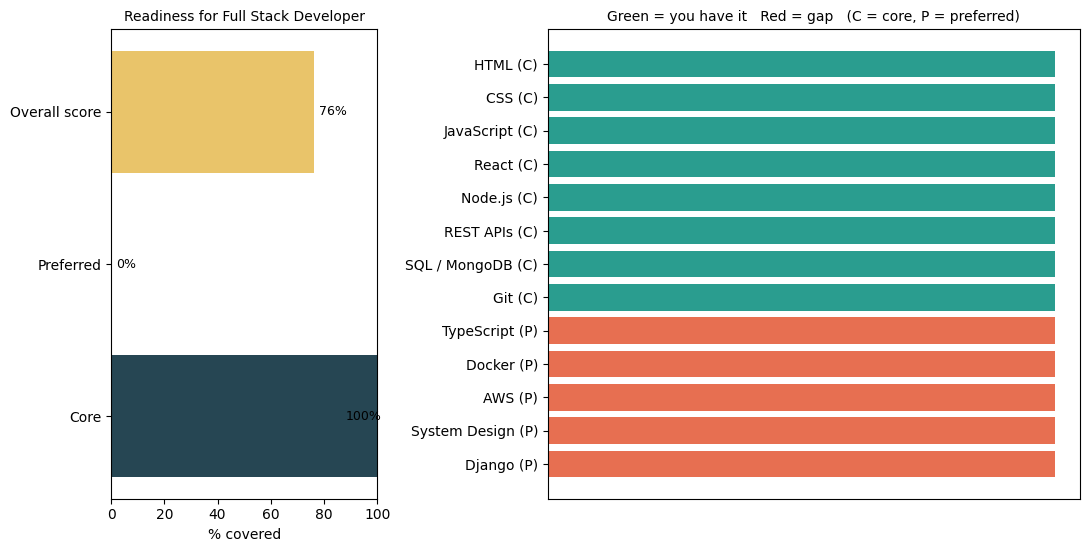

In [15]:
display(res["gap"]["table"][["requirement", "importance", "status", "matched", "est_weeks"]])
sg.plot_gap(res)

## 13. (Optional) What would the saved model say if you closed these gaps?
Re-scores your **same** model row after switching each missing skill (that is a model input column) to *present*. This reflects how the model, trained on **synthetic data**, responds to those inputs. It is an illustration, not a forecast of real hiring outcomes. Needs `X_raw` and `pred` from steps 6–7.

In [16]:
wi = sg.what_if_model(ec, model, pre, X_raw, res["gap"])
print(f"Current model P(Placed): {wi['base']:.1%}")
if len(wi["table"]):
    display(wi["table"].style.format({"p_placed_now": "{:.1%}", "p_placed_if_added": "{:.1%}", "change": "{:+.1%}"}))
    print(f"If ALL listed skills were added: {wi['all_added']:.1%}")
    sg.plot_what_if(wi)
else:
    print("None of the missing skills are input columns of your saved model, so no what-if is possible.")

Current model P(Placed): 71.6%


,skill,importance,p_placed_now,p_placed_if_added,change
0,AWS,Preferred,71.6%,76.4%,+4.8%
1,Docker,Preferred,71.6%,76.3%,+4.7%
2,Django,Preferred,71.6%,67.9%,-3.7%
3,TypeScript,Preferred,71.6%,62.1%,-9.6%


If ALL listed skills were added: 69.2%


## 14. Save the report
Writes a Markdown file and downloads it.

In [17]:
report = sg.to_markdown(res, what_if=globals().get("wi"))
fname = "skill_gap_" + res["role_name"].lower().replace(" ", "_").replace("/", "-") + ".md"
open(fname, "w", encoding="utf-8").write(report)
from google.colab import files
files.download(fname)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>